# 1강. 인공지능 기초: PyTorch로 텐서에서 첫 학습까지

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**대상**: 파이썬을 아는 딥러닝 입문자 · **분량**: 5부 · **환경**: Google Colab

**예상 시간**: 읽고 실습까지 5~7시간(어림값이며 재 본 값은 아닙니다). 코드 전체 실행은 데이터를 이미 받아 둔 상태로 Apple 실리콘 Mac의 CPU에서 약 2분이 걸렸고, Colab에서는 재 보지 못했습니다. 저장된 출력도 이 Mac CPU에서 실행한 결과입니다.

**목표: 자신만의 torch 치트시트 만들기**

이 강을 마치면 다음을 할 수 있습니다.

- 텐서를 만들고, 모양을 바꾸고, 계산한다.
- 자동 미분(autograd)이 무엇을 계산하는지 손계산과 비교해 확인한다.
- 직접 미분하던 코드가 `nn`과 `optim`으로 어떻게 짧아지는지 읽고 설명한다.
- `Dataset → DataLoader → 모델 → 손실 → 옵티마이저`로 이어지는 학습 코드를 끝까지 쓴다.

| 부 | 주제 | 다루는 내용 |
|---|---|---|
| 1부 | Tensor 만들기 | 생성, 자료형, 시드, 형 변환, 복사, GPU |
| 2부 | Tensor 계산 | in-place, 모양 바꾸기, 연산, 행렬 곱, 합치기와 나누기 |
| 3부 | Autograd | 왜 미분인가, 계산 그래프, 잎 노드, 뉴턴-랩슨법, 역전파 |
| 4부 | 코드 리뷰: 학습 코드의 진화 | 직접 미분 → autograd → `nn` → `optim` → 나만의 모듈 |
| 5부 | 첫 이미지 분류기 | 모델 구조, Dataset, DataLoader, CIFAR-10 학습과 평가 |

**필수와 선택**: 1~5부 모두 필수입니다. 제목에 `(선택)`이 붙은 절(복사 속도 측정, 뉴턴-랩슨법, 야코비안 곱, 사용자 정의 autograd 함수)은 처음 읽을 때 건너뛰어도 뒤의 내용을 따라갈 수 있습니다.

> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 5부가 빨라집니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.

**막혔을 때**: 에러가 나면 먼저 `shape`, `dtype`, `device`를 찍어 보세요. 그래도 풀리지 않으면 [PyTorch 포럼](https://discuss.pytorch.org/)에서 에러 문구를 검색하고 [공식 문서](https://docs.pytorch.org/docs/stable/)를 확인하세요.

튜토리얼은 언제나 소중합니다. [PyTorch 한국어 튜토리얼](https://tutorials.pytorch.kr/beginner/colab)에도 재미있는 노트가 많습니다.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리
import copy
import math
import random
import statistics
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

print("PyTorch:", torch.__version__)

PyTorch: 2.15.0


In [2]:
# 강의 그림을 그리는 도구입니다. 내용을 이해할 필요는 없으니 실행만 하세요.
def draw_flow(nodes: dict, edges: list, title: str = "", size: tuple = (9, 3)) -> None:
    """이름: (x, y, 글자) 상자들을 화살표로 잇는 간단한 흐름도를 그립니다."""
    fig, ax = plt.subplots(figsize=size)
    boxes = {}
    for name, (x, y, text) in nodes.items():
        boxes[name] = ax.add_patch(FancyBboxPatch((x - 0.42, y - 0.2), 0.84, 0.4, boxstyle="round,pad=0.03",
                                                  fc="#e8f0fe", ec="#3367d6"))
        ax.text(x, y, text, ha="center", va="center", fontsize=8)
    for edge in edges:
        start, end = nodes[edge[0]], nodes[edge[1]]
        color = edge[2] if len(edge) > 2 else "#444444"
        # 화살표를 상자 경계에서 잘라 글자를 가리지 않게 한다
        ax.add_patch(FancyArrowPatch(start[:2], end[:2], arrowstyle="-|>", mutation_scale=12,
                                     patchA=boxes[edge[0]], patchB=boxes[edge[1]],
                                     shrinkA=0, shrinkB=0, color=color))
    xs, ys = [n[0] for n in nodes.values()], [n[1] for n in nodes.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    ax.set_title(title)
    ax.axis("off")
    plt.show()


def draw_grid(ax, rows: int, cols: int, x0: float = 0, y0: float = 0, labels=None, color: str = "#e8f0fe") -> None:
    """격자 칸을 그립니다. labels를 주면 칸 안에 값을 적습니다."""
    for r in range(rows):
        for c in range(cols):
            ax.add_patch(Rectangle((x0 + c, y0 + rows - 1 - r), 1, 1, fc=color, ec="#3367d6"))
            if labels is not None:
                ax.text(x0 + c + 0.5, y0 + rows - 0.5 - r, str(labels[r][c]), ha="center", va="center")

---
# 1부. Tensor 만들기

## 1.1 무엇을 배울 것인가: 데이터란?

데이터는 대부분 **표**로 생각할 수 있습니다.

| 사람(행) | 키 | 몸무게 | 나이 |
|---|---|---|---|
| A | 170 | 65 | 30 |
| B | 182 | 80 | 25 |

- **행**: 각각의 케이스
- **열**: 관찰하고자 하는 지표들

> 이 표는 숫자만 놓고 보면 `2×3` **행렬**입니다. 엑셀 시트가 곧 행렬인 셈입니다.

참고 그림: [데이터의 행과 열](https://img1.daumcdn.net/thumb/R1280x0/?fname=http://t1.daumcdn.net/brunch/service/user/cqBJ/image/apw4sfrUxXkEVZ2JG3SerWwYfZY.png) · [스칼라, 벡터, 행렬 1](https://blog.kakaocdn.net/dn/ba2dyv/btrfqDxmaoV/B5pupRJg2WlppvPKqLwpGk/img.png) · [스칼라, 벡터, 행렬 2](https://blog.kakaocdn.net/dn/bJz3eK/btrfzkjpCjw/KXkAqacEHZXpzGHpnehNgk/img.png) · [행렬 연산](https://blog.kakaocdn.net/dn/bhKPAq/btqXBWfICcC/YDEYog5KNGwVEtaZkzGJFk/img.png)

## 1.2 PyTorch란?

**딥러닝 프레임워크**, 즉 딥러닝 모델을 쉽게 만들고 사용하게 해 주는 라이브러리입니다. ([소개 원문](https://velog.io/@agzg/PYTORCH%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98-%EC%82%AC%EC%9A%A9%ED%95%98%EA%B8%B0))

프레임워크마다 계산 그래프를 만드는 방식이 다릅니다.

| 방식 | 설명 | 대표 |
|---|---|---|
| **Define and Run** | 연산 그래프를 먼저 만들고, 실제 연산할 때 값을 전달해 결과를 얻음 | 초기 TensorFlow |
| **Define by Run** | 그래프를 만듦과 동시에 값이 계산됨 | PyTorch |

**Q. 무엇이 좋을까요?**

<details><summary>답</summary>

둘 다 알아 두는 것이 좋습니다. 지금은 TensorFlow도 Define by Run을 기본으로 지원하고, 최근에는 JAX도 많이 쓰입니다.
</details>

## 1.3 Tensor: PyTorch는 무엇을 하는가?

**행렬(Matrix)** 은 숫자들을 일정한 모양(행과 열)으로 배치한 것입니다. PyTorch에서는 **Tensor**, NumPy에서는 **ndarray**라는 자료구조로 표현합니다.

`2 x 2` 행렬과 `2 x 3` 행렬(행 x 열)의 예입니다.

| 1 | 1 |
|---|---|
| 1 | 1 |

| 1 | 1 | 1 |
|---|---|---|
| 1 | 1 | 1 |

**Q. 그럼 텐서는?** 숫자 → 행렬 → 그 이상으로 차원을 일반화한 것입니다. ([참고 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FqS1NF%2FbtqubStze09%2F5sbnC8DVd3aQsUULgjv6Kk%2Fimg.png))

| 차원 | 이름 | 예시 | shape 예 |
|---|---|---|---|
| 0 | 스칼라 | 손실값 하나 | `()` |
| 1 | 벡터 | 키, 몸무게, 나이 | `(3,)` |
| 2 | 행렬 | 표 데이터 | `(100, 3)` |
| 3 | 3차원 텐서 | 컬러 이미지 한 장 | `(3, 32, 32)` |
| 4 | 4차원 텐서 | 이미지 묶음(배치) | `(16, 3, 32, 32)` |

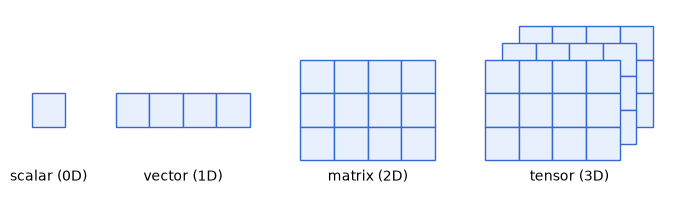

In [3]:
fig, ax = plt.subplots(figsize=(9, 2.4))
draw_grid(ax, 1, 1, x0=0, y0=1)
draw_grid(ax, 1, 4, x0=2.5, y0=1)
draw_grid(ax, 3, 4, x0=8, y0=0)
for depth in (2, 1, 0):
    draw_grid(ax, 3, 4, x0=13.5 + depth * 0.5, y0=depth * 0.5)
for x, name in [(0.5, "scalar (0D)"), (4.5, "vector (1D)"), (10, "matrix (2D)"), (16, "tensor (3D)")]:
    ax.text(x, -0.6, name, ha="center")
ax.set_xlim(-0.5, 19.5)
ax.set_ylim(-1, 4.5)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

### Tensor는 어떤 객체인가?

텐서는 값만 담은 배열이 아니라, 값(`data`), 미분값(`grad`), 만들어진 연산(`grad_fn`)까지 함께 가진 객체입니다. 뒤의 3부에서 이 속성들을 쓰게 됩니다.

In [4]:
x = torch.rand(5)
print(type(x))
print(x.data)
print(x.grad)       # 아직 미분하지 않았으므로 None
print(x.grad_fn)    # 사용자가 직접 만들었으므로 None

# 어떤 기능이 있는지는 dir로 볼 수 있다
methods = [name for name in dir(torch.Tensor) if not name.startswith("_")]
print(f"공개 속성과 메서드 {len(methods)}개, 앞의 10개:", methods[:10])

<class 'torch.Tensor'>
tensor([0.0540, 0.5228, 0.3388, 0.6964, 0.1918])
None
None
공개 속성과 메서드 604개, 앞의 10개: ['H', 'T', 'abs', 'abs_', 'absolute', 'absolute_', 'acos', 'acos_', 'acosh', 'acosh_']


## 1.4 다양한 방법으로 만들기

### 영행렬

0으로 채워진 `5x3` 텐서를 만듭니다. PyTorch의 기본 데이터 타입은 **32비트 부동소수점**입니다.

In [5]:
z = torch.zeros(5, 3)
print(z)
print(z.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
torch.float32


### 그 외의 생성 함수

그 외에도 다양한 기능들이 있습니다. `torch.empty`는 메모리를 초기화하지 않으므로 값이 무엇이든 나올 수 있습니다.

In [6]:
print(torch.rand(10))                 # 0~1 균등 분포
print(torch.randn(10))                # 평균 0, 표준편차 1
print(torch.empty(4))                 # 크기 4의 초기화되지 않은 텐서
print(torch.empty(4).size())
print(torch.empty(size=(4, 5)).size())
print(torch.empty((4, 5)).size())     # 튜플로 크기를 줘도 같다
print(torch.full((1, 2), 3.14))       # (1, 2) 크기를 3.14로 채움
print(torch.eye(3))                   # 단위행렬
print(torch.eye(5, 3))                # 직사각형도 가능
print(torch.empty(2, 2).uniform_(-1, 1))    # 원하는 범위의 균등 분포

tensor([0.3909, 0.5758, 0.1376, 0.4891, 0.5504, 0.0701, 0.6006, 0.9319, 0.4269,
        0.4209])
tensor([-0.7111, -0.0782,  0.6357,  1.4939,  1.0197, -0.0885,  0.4359, -1.5442,
        -0.3147,  2.2058])
tensor([0., 0., 0., 0.])
torch.Size([4])
torch.Size([4, 5])
torch.Size([4, 5])
tensor([[3.1400, 3.1400]])
tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.],
        [0., 0., 0.],
        [0., 0., 0.]])
tensor([[ 0.5747, -0.1928],
        [-0.1384, -0.0786]])


### 1로 꽉 찬 행렬과 dtype

`ones`는 1로 가득 찬 텐서입니다. `dtype`을 지정하면 기본값(`float32`)을 바꿀 수 있습니다.

[PyTorch가 지원하는 자료형 살펴보기](https://docs.pytorch.org/docs/stable/tensors.html)

In [7]:
i = torch.ones((5, 3), dtype=torch.int16)
print(i)

tensor([[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]], dtype=torch.int16)


### 랜덤과 시드

같은 시드에서 시작하면 같은 난수가 다시 나옵니다.

In [8]:
torch.manual_seed(1729)
r1 = torch.rand(2, 2)
print("랜덤 tensor 값:")
print(r1)

r2 = torch.rand(2, 2)
print("\n다른 랜덤 tensor 값:")
print(r2)                       # 시드를 다시 고정하지 않았으므로 새로운 값

torch.manual_seed(1729)
r3 = torch.rand(2, 2)
print("\nr1과 일치:")
print(r3)                       # 같은 시드에서 다시 시작했으므로 r1과 같은 값

랜덤 tensor 값:
tensor([[0.3126, 0.3791],
        [0.3087, 0.0736]])

다른 랜덤 tensor 값:
tensor([[0.4216, 0.0691],
        [0.2332, 0.4047]])

r1과 일치:
tensor([[0.3126, 0.3791],
        [0.3087, 0.0736]])


### 재현성(Reproducibility)

랜덤 시드를 고정하는 것은 매우 중요합니다. 실험을 재현하기 위한 것으로, 생각보다 많은 문제를 일으키는 부분입니다.

요약하면 **한 번에 고정하는 방법은 없습니다**. 라이브러리마다 난수 생성기가 따로 있기 때문입니다. `torch.manual_seed`는 CPU와 GPU 등 모든 장치의 PyTorch 난수를 고정하지만, 파이썬과 NumPy의 난수는 따로 고정해야 합니다.

이렇게 해도 공식 문서는 PyTorch 버전이나 플랫폼이 다르면 완전한 재현을 보장하지 않는다고 적습니다. 목표는 **같은 환경에서 같은 결과**입니다. ([공식 문서](https://docs.pytorch.org/docs/stable/notes/randomness.html))

- `cudnn.benchmark = False`: 실행할 때마다 GPU 합성곱 알고리즘이 다르게 선택되는 일을 막습니다.
- `cudnn.deterministic = True`: 고른 합성곱 알고리즘 자체가 같은 결과를 내게 합니다.
- `torch.use_deterministic_algorithms(True)`: 더 엄격한 설정입니다. 결정론적 구현을 쓰고, 그런 구현이 없는 연산은 에러를 냅니다. 아래 함수에는 넣지 않았으니 정말 필요할 때 켜세요.
- `DataLoader`를 쓸 때의 설정은 5부에서 다룹니다.

아래 블록은 잘 저장해 두었다가 다른 프로젝트에서도 쓰세요.

In [9]:
def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)            # CPU와 모든 GPU의 PyTorch 난수
    # 속도를 조금 희생하고 GPU 연산의 재현성을 높인다
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

In [10]:
print(torch.rand(size=(2, 2)))                    # 0과 1 사이의 균등 분포
print(torch.randn(2, 2))                          # 평균 0, 표준편차 1의 정규 분포
print(torch.randperm(10))                         # 0~9(10 미포함)의 정수를 무작위로 섞음
print(torch.randint(low=0, high=10, size=(2, 4))) # 0 이상 10 미만의 정수 난수

tensor([[0.3126, 0.3791],
        [0.3087, 0.0736]])
tensor([[-1.3975,  1.4364],
        [-0.1068, -0.8413]])
tensor([7, 2, 3, 0, 5, 9, 4, 1, 8, 6])
tensor([[4, 9, 7, 4],
        [8, 9, 6, 2]])


### 3차원 이상의 행렬을 만들고 크기 확인하기

In [11]:
z = torch.zeros(5, 3, 4, 10, 9)
print(z.shape)
print(z.size())

torch.Size([5, 3, 4, 10, 9])
torch.Size([5, 3, 4, 10, 9])


## 1.5 형 변환(Type casting)

- 실수의 기본 자료형은 `torch.float32`입니다. NumPy의 기본(`float64`)과 다릅니다.
- 리스트로 만들면 그 데이터의 자료형을 따라갑니다. 정수면 `torch.int64`입니다.
- 신경망 입력은 보통 `float32`, 분류 정답은 보통 `int64`입니다. 자료형이 안 맞으면 에러가 나므로 꼭 확인하세요.

In [12]:
print(torch.tensor([[1., -1.], [1., -1.]]))                       # 리스트를 텐서로

x = torch.tensor([[1, -1], [1, -1]])
print(x.dtype)                                                    # 리스트의 자료형을 따라감

x = torch.tensor([[1, -1], [1, -1]], dtype=torch.float32)         # 직접 지정
print(x, x.dtype)

print(torch.tensor([1, 2]).float().dtype)                         # 형 변환
print(torch.tensor([1, 2]).to(torch.float64).dtype)               # 형 변환

tensor([[ 1., -1.],
        [ 1., -1.]])
torch.int64
tensor([[ 1., -1.],
        [ 1., -1.]]) torch.float32
torch.float32
torch.float64


In [13]:
# 축별 데이터 개수가 맞지 않으면 동작하지 않습니다: 일부러 일으킨 에러
try:
    torch.tensor([[1., -1.], [1., -1., 2.8]])
except ValueError as e:
    print("ValueError:", e)

ValueError: expected sequence of length 2 at dim 1 (got 3)


In [14]:
# NumPy 행렬을 텐서로 바꿀 수도 있습니다
np_array = np.array([[1, 2, 3], [4, 5, 6]])
x = torch.tensor(np_array)
print(x)

print(x[1][2])     # 위치의 요소값 가져오기
x[0][1] = 8        # 특정 위치 값 바꾸기
print(x)
print(x[:, 0:2])   # 슬라이싱

tensor([[1, 2, 3],
        [4, 5, 6]])
tensor(6)
tensor([[1, 8, 3],
        [4, 5, 6]])
tensor([[1, 8],
        [4, 5]])


### NumPy와 메모리를 공유하는 변환

- `torch.tensor(a)`: 값을 **복사**합니다.
- `torch.from_numpy(a)`: 메모리를 **공유**합니다. NumPy 배열을 바꾸면 텐서도 바뀝니다.
- `torch.as_tensor(a)`: 가능하면 **공유**합니다. 복사 비용을 피하고 싶은 큰 데이터에 씁니다. 리스트처럼 공유할 수 없는 입력은 복사합니다.

되돌릴 때는 `.numpy()`를 씁니다. ([as_tensor 참고](https://jh-bk.tistory.com/46))

In [15]:
n = np.ones(5)
t = torch.from_numpy(n)
np.add(n, 1, out=n)
print(f"t: {t}")
print(f"n: {n}")

a = np.array([1, 2, 3])
b = torch.as_tensor(a)
a[0] = 99
print(b)

x_np = torch.from_numpy(np_array)
print(type(x_np.numpy()))      # 다시 되돌리기도 가능

t: tensor([2., 2., 2., 2., 2.], dtype=torch.float64)
n: [2. 2. 2. 2. 2.]
tensor([99,  2,  3])
<class 'numpy.ndarray'>


### 값 하나 꺼내기: `.item()`

원소 하나짜리 텐서를 파이썬 숫자로 바꿉니다. 아래에는 파이썬의 walrus 연산자(`:=`) 연습도 함께 있습니다.

In [16]:
np_array = np.array([[1, 2, 3], [4, 5, 6]])
x = torch.tensor(np_array)
print(x)

# walrus 연산자: 값을 저장하면서 바로 사용
print(y := x[1][2].item())
print(type(y))

# walrus 연산자를 안 쓰면
y = x[1][2].item()
print(y)
print(type(y))

tensor([[1, 2, 3],
        [4, 5, 6]])
6
<class 'int'>
6
<class 'int'>


## 1.6 비교하기: eq, equal, allclose

| 함수 | 의미 |
|---|---|
| `torch.ne` (= `torch.not_equal`) | 원소별 `!=` |
| `torch.eq` | 원소별 `==` |
| `torch.le` (= `torch.less_equal`) | 원소별 `<=` |
| `torch.ge` (= `torch.greater_equal`) | 원소별 `>=` |
| `torch.equal` | 두 텐서의 크기와 값이 모두 같으면 `True`, 아니면 `False` |
| `torch.allclose` | 정밀도 이내에서 같은 것으로 봄(부동소수점용) |

In [17]:
a = torch.tensor([[2, 5], [4, 3]])
b = torch.tensor([[2, 8], [2, 3]])
print(torch.ne(a, b))   # !=
print(torch.eq(a, b))   # ==
print(torch.le(a, b))   # <=
print(torch.ge(a, b))   # >=

print(torch.equal(a, b))
print(torch.all(torch.eq(a, b)))

tensor([[False,  True],
        [ True, False]])
tensor([[ True, False],
        [False,  True]])
tensor([[ True,  True],
        [False,  True]])
tensor([[ True, False],
        [ True,  True]])
False
tensor(False)


In [18]:
print(0.1 * 0.1 == 0.01)   # 부동소수점: 실수는 ==로 비교하면 안 된다

False


In [19]:
# torch.allclose(input, other, rtol=1e-05, atol=1e-08, equal_nan=False) -> bool
print(torch.allclose(torch.tensor([10000., 1e-07]), torch.tensor([10000.1, 1e-08])))
print(torch.allclose(torch.tensor([10000., 1e-08]), torch.tensor([10000.1, 1e-09])))

print(torch.allclose(torch.tensor([1.0, float("nan")]), torch.tensor([1.0, float("nan")])))
print(torch.allclose(torch.tensor([1.0, float("nan")]), torch.tensor([1.0, float("nan")]), equal_nan=True))

# isclose는 원소별로 결과를 돌려준다(잘 쓰지는 않음)
print(torch.isclose(torch.tensor([1.0]), torch.tensor([1.00000001])))

False
True
False
True
tensor([True])


## 1.7 텐서 복사하기

가장 찾기 어려운 버그 중 하나입니다. **어떤 방법이 원본과 메모리를 공유하는지** 알아 두세요.

| 방법 | 메모리 | 계산 그래프 |
|---|---|---|
| `x.clone()` | 새로 할당 | 계산 그래프에 남음 |
| `x.detach()` | **공유** | 계산 그래프에서 빠짐 |
| `x.detach().clone()` | 새로 할당 | 계산 그래프에서 빠짐 |
| `x.data` | 공유 | 빠짐. 미분 오류를 숨길 수 있어 권장하지 않음 |

`detach`로 만든 텐서는 저장 공간(storage)을 공유하므로, 값을 바꾸면 원본도 똑같이 변합니다.

**Q. 텐서를 완전히 독립된 사본으로 복사하는 방법 중 옳은 것은?** ([참고 1](https://seducinghyeok.tistory.com/10), [참고 2](https://hongl.tistory.com/363))

<details><summary>답</summary>

`x.detach().clone()`입니다. 먼저 끊고 복사하므로 불필요한 그래프 연산이 없습니다. `x.clone().detach()`도 결과는 같습니다.
</details>

In [20]:
x = torch.rand(size=(3, 3))
print(x)

y = x.clone().detach()       # 맞는 방법
print(torch.equal(x, y))

y = x.detach().clone()       # 조금 더 효율적인 맞는 방법
print(torch.equal(x, y))

# 권장하지 않는 방법: 경고 메시지가 무엇을 권하는지 읽어 보세요
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    y = x.new_tensor(x)
    print(torch.equal(x, y))
    y = torch.tensor(x)
    print(torch.equal(x, y))
print("경고:", caught[0].message)

# 동작은 하지만 굳이 쓸 이유가 없는 방법
y = torch.empty_like(x).copy_(x)
print(torch.equal(x, y))

tensor([[0.6839, 0.0703, 0.5105],
        [0.9451, 0.2359, 0.1979],
        [0.3327, 0.6146, 0.5999]])
True
True
True
True
경고: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
True


In [21]:
# 깊은 복사를 활용하는 방법: 복사본도 잎 노드이고 requires_grad를 유지한다
x = torch.ones(10, requires_grad=True)
x_deepcopy = copy.deepcopy(x)
print(x, "x")
print(x_deepcopy, "x deepcopy")

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], requires_grad=True) x
tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], requires_grad=True) x deepcopy


### `torch.tensor`와 `torch.Tensor`의 차이

이름은 비슷하지만 다릅니다. **새 코드에서는 `torch.tensor`를 쓰세요.**

| | `torch.tensor` | `torch.Tensor` |
|---|---|---|
| 정체 | 함수 | 클래스 |
| 정수 리스트 입력 | 정수를 유지 | 실수로 변환(`float32`) |
| 리스트 입력 | 값을 복사 | 값을 복사 |
| NumPy 입력 | 값을 복사 | `float32`는 **같은 메모리를 사용**, 다른 자료형은 복사 |
| 실수 텐서 입력 | 값을 복사 | **같은 메모리를 그대로 사용** |

([참고 그림](https://velog.velcdn.com/images%2Fminchoul2%2Fpost%2Fc3a629f4-a0d7-49ee-88b5-c93401a8b93c%2Fimage.png))

In [22]:
print(torch.tensor([1]).dtype, torch.Tensor([1]).dtype)

# torch.tensor: 값을 복사하여 생성한다
original_data = torch.tensor([1.0])
new_data = original_data.detach().clone()   # torch.tensor(텐서)와 같은 동작의 권장 표현
original_data[0] = 2
print(f"tensor 방식  original: {original_data}, new: {new_data}")

# torch.Tensor에 실수 텐서를 주면 같은 메모리를 쓴다
original_data = torch.tensor([1.0])
new_data = torch.Tensor(original_data)
original_data[0] = 2
print(f"Tensor 방식  original: {original_data}, new: {new_data}")
assert new_data[0] == 2

# torch.Tensor에 리스트를 주면 값을 복사한다
original_data = [1]
new_data = torch.Tensor(original_data)
original_data[0] = 2
print(f"리스트 입력  original: {original_data}, new: {new_data}")

# NumPy float32 배열은 메모리를 공유하고, float64 배열은 변환되므로 복사된다
array32 = np.array([1.0, 2.0], dtype=np.float32)
from_array32 = torch.Tensor(array32)
array32[0] = 99
print(f"NumPy float32 입력  new: {from_array32}")
assert from_array32[0] == 99

array64 = np.array([1.0, 2.0], dtype=np.float64)
from_array64 = torch.Tensor(array64)
array64[0] = 99
print(f"NumPy float64 입력  new: {from_array64}")
assert from_array64[0] == 1

torch.int64 torch.float32
tensor 방식  original: tensor([2.]), new: tensor([1.])
Tensor 방식  original: tensor([2.]), new: tensor([2.])
리스트 입력  original: [2], new: tensor([1.])
NumPy float32 입력  new: tensor([99.,  2.])
NumPy float64 입력  new: tensor([1., 2.])


### (선택) 성능 측정은 어떻게 할까?

복사 방법들의 속도를 직접 재 봅시다. 텐서 길이를 늘려 가며 `time.perf_counter()`로 복사 한 번의 시간을 200번 재고, 튀는 값에 덜 흔들리도록 중앙값을 그립니다. 값의 범위가 넓어 두 축 모두 로그 눈금을 씁니다. **선이 낮을수록 시간이 적게 걸린 것입니다.**

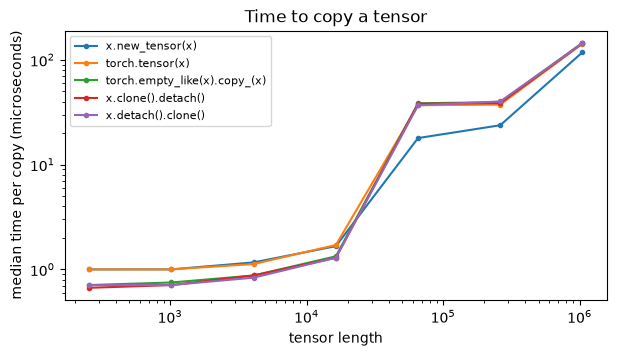

In [23]:
def measure_copy(copy_fn, length: int, repeats: int = 200) -> float:
    """복사 한 번에 걸린 시간의 중앙값(초)을 돌려줍니다."""
    source = torch.randn(length)
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        copy_fn(source)
        samples.append(time.perf_counter() - start)
    return statistics.median(samples)


copy_methods = {
    "x.new_tensor(x)": lambda x: x.new_tensor(x),
    "torch.tensor(x)": lambda x: torch.tensor(x),
    "torch.empty_like(x).copy_(x)": lambda x: torch.empty_like(x).copy_(x),
    "x.clone().detach()": lambda x: x.clone().detach(),
    "x.detach().clone()": lambda x: x.detach().clone(),
}
lengths = [2 ** power for power in range(8, 21, 2)]

plt.figure(figsize=(7, 3.5))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")    # 권장하지 않는 복사 방법의 경고는 이미 확인했으므로 숨김
    for name, copy_fn in copy_methods.items():
        times_us = [measure_copy(copy_fn, length) * 1e6 for length in lengths]
        plt.plot(lengths, times_us, "o-", markersize=3, label=name)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("tensor length")
plt.ylabel("median time per copy (microseconds)")
plt.title("Time to copy a tensor")
plt.legend(fontsize=8)
plt.show()

저장된 그래프에서는 짧은 텐서일 때 `torch.tensor(x)`와 `x.new_tensor(x)`가 조금 느립니다. 길이가 6만을 넘는 구간에서는 `x.new_tensor(x)`가 오히려 빠르게 나왔는데, 같은 코드를 따로 두 번 돌렸을 때는 이 차이가 없었으니 실행마다 흔들리는 값으로 보입니다. 측정은 기계와 실행에 따라 달라지니 한 번의 결과에 의미를 두지 마세요. 복사 방법은 속도보다 위 표의 메모리와 그래프 동작으로 고르면 됩니다.

## 1.8 GPU 사용하기

**Q. 왜 코랩을 쓸까요?** 그래픽 카드를 써야 하기 때문입니다.

**Q. 그래픽 카드는 왜 써야 하나요?** 딥러닝 연산은 수없이 반복되는 작은 병렬 처리가 필요하기 때문입니다.

`런타임 유형 변경 → 하드웨어 가속기`가 무엇으로 설정되어 있나요? **T4 GPU**로 바꾸고 아래를 다시 실행해 보세요.

Apple 실리콘 Mac에서 직접 실행한다면 `"mps"` 장치도 있습니다. 단, MPS는 `float64`를 지원하지 않아 이 절의 `float64` 예제가 에러를 냅니다. 그래서 이번 강의의 코드는 `cuda`가 없으면 `cpu`로 실행합니다. 3강부터는 `mps`도 함께 고릅니다.

In [24]:
if torch.cuda.is_available():
    x = "cuda"
else:
    x = "cpu"
device = torch.device(x)
print(device)

# 한 줄로 쓰면 다음과 같습니다
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
print("Apple MPS 사용 가능:", torch.backends.mps.is_available())

cpu
cpu
Apple MPS 사용 가능: True


In [25]:
# 출력되는 내용에 device가 바뀌나요?
torch.ones([2, 4], dtype=torch.float64, device=device)

tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]], dtype=torch.float64)

In [26]:
# to 메서드로 옮길 수도 있습니다. 원본을 바꾸지 않고 새 텐서를 돌려주므로 대입해야 합니다
x = torch.tensor([[1., -1.], [1., -1.]])
x = x.to(device)
print(x.to(device, dtype=torch.float64).dtype)   # 자료형을 같이 지정할 수도 있음

if torch.cuda.is_available():
    print(x.cuda().device)                       # x.cuda()도 같은 일을 함

# GPU에 있는 값도 꺼낼 수 있다
print(x[0][0].item())

torch.float64
1.0


In [27]:
def time_matmul(dev: torch.device, size: int = 2000) -> float:
    """행렬 곱 한 번에 걸리는 시간(초)을 잽니다."""
    a = torch.rand(size, size, device=dev)
    start = time.perf_counter()
    result = a @ a
    if dev.type == "cuda":
        # GPU 연산은 비동기이므로 끝날 때까지 기다려야 시간이 정확하다
        torch.cuda.synchronize()
    return time.perf_counter() - start

print(f"CPU: {time_matmul(torch.device('cpu')):.4f}초")
if torch.cuda.is_available():
    print(f"GPU: {time_matmul(device):.4f}초")
else:
    print("GPU 없음: 런타임 유형을 T4 GPU로 바꾸면 비교할 수 있습니다.")

CPU: 0.0104초
GPU 없음: 런타임 유형을 T4 GPU로 바꾸면 비교할 수 있습니다.


### 텐서의 세 가지 속성: shape, dtype, device

에러가 나면 가장 먼저 이 셋을 찍어 보세요. **계산에 쓰는 텐서는 모두 같은 장치에 있어야 합니다.**

In [28]:
tensor = torch.rand(3, 4)
print(f"Shape of tensor: {tensor.shape}")       # .size()와 같음
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")
print(f"Number of dimension: {tensor.ndim}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu
Number of dimension: 2


## 1.9 유용한 생성 기능들

기존 텐서와 **같은 자료형, 같은 장치**로 새 텐서를 만들 때 씁니다. GPU 코드에서 장치를 깜빡해 나는 에러를 줄여 줍니다.

In [29]:
original_tensor = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32, device="cpu")

# new()는 권장하지 않습니다. 아래의 new_* 계열을 쓰세요
print(original_tensor.new(2, 2).shape)
print(original_tensor.new_zeros(2, 2))
print(original_tensor.new_ones(2, 2))
print(original_tensor.new_full((2, 2), fill_value=7.0))
print(original_tensor.new_zeros(2, 2).dtype, original_tensor.new_zeros(2, 2).device)
# 참고: https://docs.pytorch.org/docs/stable/generated/torch.Tensor.new_tensor.html

torch.Size([2, 2])
tensor([[0., 0.],
        [0., 0.]])
tensor([[1., 1.],
        [1., 1.]])
tensor([[7., 7.],
        [7., 7.]])
torch.float32 cpu


In [30]:
data = torch.zeros(3, 4)
print(torch.empty_like(data).shape)
print(torch.zeros_like(data))
print(torch.ones_like(data))
print(torch.full_like(data, 2.717))
print(torch.rand_like(data))
print(torch.randn_like(data))

torch.Size([3, 4])
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])
tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
tensor([[2.7170, 2.7170, 2.7170, 2.7170],
        [2.7170, 2.7170, 2.7170, 2.7170],
        [2.7170, 2.7170, 2.7170, 2.7170]])
tensor([[0.5869, 0.3581, 0.2789, 0.8569],
        [0.3741, 0.1539, 0.8845, 0.6871],
        [0.5157, 0.6010, 0.3605, 0.1006]])
tensor([[-0.1450,  1.5051, -0.8434, -0.7884],
        [ 1.0885, -0.6670,  0.7155, -1.3488],
        [-0.7695,  1.4119,  0.6526, -0.1329]])


### 수열 만들기

`torch.range`는 끝값을 포함하지만 **폐기 예정(deprecated)** 입니다. 파이썬과 NumPy처럼 끝값을 포함하지 않는 `torch.arange`를 쓰세요.

In [31]:
# arange(시작(생략 시 0), 끝(미포함), 간격(생략 시 1))
print(torch.arange(5))
print(torch.arange(1, 4))
print(torch.arange(1, 4, 0.2))
print(torch.arange(1, 4.5, 0.5))     # torch.range(1, 4, 0.5)와 같은 결과

print("-" * 30)
print(torch.linspace(1, 4, 20))      # 1부터 4까지 20개로 자르면
print(torch.logspace(1, 4, 20))      # 10^1부터 10^4까지 로그 간격으로 20개

tensor([0, 1, 2, 3, 4])
tensor([1, 2, 3])
tensor([1.0000, 1.2000, 1.4000, 1.6000, 1.8000, 2.0000, 2.2000, 2.4000, 2.6000,
        2.8000, 3.0000, 3.2000, 3.4000, 3.6000, 3.8000])
tensor([1.0000, 1.5000, 2.0000, 2.5000, 3.0000, 3.5000, 4.0000])
------------------------------
tensor([1.0000, 1.1579, 1.3158, 1.4737, 1.6316, 1.7895, 1.9474, 2.1053, 2.2632,
        2.4211, 2.5789, 2.7368, 2.8947, 3.0526, 3.2105, 3.3684, 3.5263, 3.6842,
        3.8421, 4.0000])
tensor([   10.0000,    14.3845,    20.6914,    29.7635,    42.8133,    61.5848,
           88.5867,   127.4275,   183.2981,   263.6651,   379.2690,   545.5594,
          784.7599,  1128.8379,  1623.7767,  2335.7214,  3359.8184,  4832.9302,
         6951.9277, 10000.0000])


### 그 밖의 자료형

텐서로 복소수도 만들 수 있습니다. `double`, `byte`, `half`, `char`, `int`, `bool` 등 다양한 자료형이 있으니 [공식 문서](https://docs.pytorch.org/docs/stable/tensors.html)를 꼭 참고하세요. 다른 코드에서 `torch.FloatTensor([1, 2, 3])` 같은 표현을 만나면 `float32` 텐서를 만드는 것으로 읽으면 됩니다. 새 코드에서는 `torch.tensor(..., dtype=torch.float32)`를 쓰세요.

In [32]:
real = torch.tensor([1, 2, 3], dtype=torch.float32)
img = torch.tensor([4, 5, 6], dtype=torch.float32)
print(torch.complex(real, img))

tensor([1.+4.j, 2.+5.j, 3.+6.j])


### 실습 1

1. 평균 0, 표준편차 1의 난수로 `(4, 3)` 텐서 `m`을 `float64` 자료형으로 만드세요.
2. `m`과 메모리를 공유하지 않는 사본 `m2`를 만들고, `m2`를 전부 0으로 바꿔도 `m`이 그대로인지 확인하세요.

In [33]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
m = torch.randn(4, 3, dtype=torch.float64)
before = m.sum().item()
m2 = m.detach().clone()
m2.zero_()
assert m2.sum().item() == 0
assert m.sum().item() == before
print("m은 그대로입니다:", m.sum().item() == before)
```
</details>

---
# 2부. Tensor 계산

## 2.1 in-place 연산: 뒤에 `_`가 붙은 경우

메서드 이름 뒤에 `_`가 있으면 `inplace=True`와 같습니다. **원본 자체를 바꿉니다.**

> in-place 연산은 메모리를 일부 절약하지만, 미분 계산에 필요한 값을 덮어쓰면 문제가 생길 수 있습니다. 그래서 학습 코드에서는 권장하지 않습니다.

In [34]:
# 파이썬에서 먼저 확인
x = 4
print(x + 5)
print(x)            # 값은 그대로

x = [1, 2, 34]
x[0] += 1
print(x)            # 리스트는 원본이 바뀜

# x = func(x)   원본을 두고 새 값을 받음
# x.func()      원본이 바뀜

9
4
[2, 2, 34]


In [35]:
a = torch.randn(4, 4)
print(a)
a.fill_(3.5)        # a = a.fill(3.5)는 없는 메서드
print(a)
a.add_(5)
print(a)
a.add_(-10)
print(a.abs())      # 새 텐서를 돌려줌
print(a)            # 원본은 그대로
print(a.abs_())     # 원본을 바꿈(pandas의 inplace=True)
print(a)

# 생각해 보기: sub, mul, div와 sub_, mul_, div_의 차이는? -, *, /는 어느 쪽일까요?

tensor([[-0.8857, -1.2002,  1.3299,  1.8301],
        [-0.7545, -0.8600,  0.2064, -0.8586],
        [-0.1808, -0.1665, -1.6289,  0.1416],
        [ 0.4278,  0.7050, -0.6267,  1.0667]])
tensor([[3.5000, 3.5000, 3.5000, 3.5000],
        [3.5000, 3.5000, 3.5000, 3.5000],
        [3.5000, 3.5000, 3.5000, 3.5000],
        [3.5000, 3.5000, 3.5000, 3.5000]])
tensor([[8.5000, 8.5000, 8.5000, 8.5000],
        [8.5000, 8.5000, 8.5000, 8.5000],
        [8.5000, 8.5000, 8.5000, 8.5000],
        [8.5000, 8.5000, 8.5000, 8.5000]])
tensor([[1.5000, 1.5000, 1.5000, 1.5000],
        [1.5000, 1.5000, 1.5000, 1.5000],
        [1.5000, 1.5000, 1.5000, 1.5000],
        [1.5000, 1.5000, 1.5000, 1.5000]])
tensor([[-1.5000, -1.5000, -1.5000, -1.5000],
        [-1.5000, -1.5000, -1.5000, -1.5000],
        [-1.5000, -1.5000, -1.5000, -1.5000],
        [-1.5000, -1.5000, -1.5000, -1.5000]])
tensor([[1.5000, 1.5000, 1.5000, 1.5000],
        [1.5000, 1.5000, 1.5000, 1.5000],
        [1.5000, 1.5000, 1.5000, 1.5000

## 2.2 contiguous: 메모리에서도 붙어 있는가

저장 공간(storage)은 **어떤 자료형의 연속적인 1차원 배열**입니다. 행렬이 붙어 있는 것처럼 보여도, 메모리를 읽는 순서까지 차례대로인지는 별개의 문제입니다. 그 여부가 `contiguous`입니다.

`transpose`는 값을 옮기지 않고 **읽는 순서만** 바꾸므로 연속성이 깨집니다. ([참고 글](https://velog.io/@damab/pytorch-Contiguous-tensors), [참고 그림](https://blog.kakaocdn.net/dn/bDhnFi/btrsQpLIQao/5g8JFdMPlAS4kBmZ2mJMaK/img.jpg))

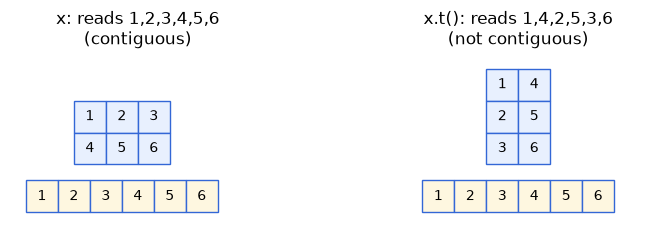

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.2))
values = [[1, 2, 3], [4, 5, 6]]
storage = [1, 2, 3, 4, 5, 6]
draw_grid(axes[0], 2, 3, x0=0, y0=1.5, labels=values)
draw_grid(axes[0], 1, 6, x0=-1.5, y0=0, labels=[storage], color="#fef7e0")
axes[0].set_title("x: reads 1,2,3,4,5,6\n(contiguous)")
draw_grid(axes[1], 3, 2, x0=1, y0=1.5, labels=[[1, 4], [2, 5], [3, 6]])
draw_grid(axes[1], 1, 6, x0=-1, y0=0, labels=[storage], color="#fef7e0")
axes[1].set_title("x.t(): reads 1,4,2,5,3,6\n(not contiguous)")
for ax in axes:
    ax.set_xlim(-2, 6)
    ax.set_ylim(-0.3, 5)
    ax.set_aspect("equal")
    ax.axis("off")
plt.show()

In [37]:
y = torch.ones(6, 3)
y.transpose_(0, 1)
print(y.is_contiguous())    # False
y = y.contiguous()          # 강제로 contiguous하게 만듦
print(y.is_contiguous())    # True

False
True


In [38]:
# 이미 연속이면 contiguous()는 메모리를 새로 만들지 않고, 연속이 아니면 복사한다
print(y.contiguous().data_ptr() == y.data_ptr())       # True: 같은 메모리

not_contiguous = y.t()
print(not_contiguous.contiguous().data_ptr() == not_contiguous.data_ptr())   # False: 복사됨

True
False


## 2.3 reshape와 view: 모양을 재가공하자

- `view`: 원본의 보는 방향만 바꿉니다. **항상 원본과 메모리를 공유**합니다. 연속인 텐서에서는 언제나 동작하고, 연속이 아니면 메모리 배치와 맞는 모양일 때만 동작합니다.
- `reshape`: 항상 동작합니다. 대신 **공유 여부를 보장하지 않습니다**. 편합니다.

즉, 동작의 결과를 놓고 보면 다음 둘의 값은 같습니다.

```python
y1 = x.reshape(S)
y2 = x.contiguous().view(S)
```

차원 때문에 스트레스를 많이 받는다면 `einops`, `einsum`을 살펴보세요.

In [39]:
print("-" * 30)
x = torch.rand(2, 3, 4)
print(x.view(2, -1).shape)      # -1은 "나머지를 알아서 계산"

print("-" * 30)
x = torch.rand(2, 3, 4)
print(x.reshape(2, -1).shape)

# view는 붙어 있는 차원을 떼어낼 때 자주 쓴다: [B*C, H, W] -> [B, C, H, W]

------------------------------
torch.Size([2, 12])
------------------------------
torch.Size([2, 12])


In [40]:
z = torch.zeros(3, 2)
y = z.t()
print(y.size())

# 연속이 아니라 view는 에러가 난다: 일부러 일으킨 에러
try:
    y.view(6)
except RuntimeError as e:
    print("RuntimeError:", str(e)[:90], "...")

y_reshape = y.reshape(6)    # 동작하지만 복사본이므로 원본과 연결되지 않음
print(y_reshape)

y2 = y.contiguous()
y_view = y2.view(6)
y_view[0] = 9               # view는 y2와 메모리를 공유하므로 y2도 바뀜
print(y_view)
print(torch.equal(y_reshape, y_view))
print(y2)                   # 바뀜
print(y)                    # 그대로

torch.Size([2, 3])
RuntimeError: view size is not compatible with input tensor's size and stride (at least one dimension sp ...
tensor([0., 0., 0., 0., 0., 0.])
tensor([9., 0., 0., 0., 0., 0.])
False
tensor([[9., 0., 0.],
        [0., 0., 0.]])
tensor([[0., 0., 0.],
        [0., 0., 0.]])


## 2.4 squeeze와 unsqueeze: 필요 없는 차원을 넣거나 빼자

- `squeeze`: 크기가 1인 차원을 없앱니다.
- `unsqueeze`: 크기가 1인 차원을 끼워 넣습니다.

PyTorch 이미지 배치의 기본 순서는 `(배치, 채널, 높이, 너비)`, 줄여서 `BCHW`입니다.

> **중요**: 차원을 지정하지 않은 `squeeze()`는 배치 크기가 1일 때 배치 차원까지 지웁니다. **항상 `dim`을 적으세요.**

In [41]:
x = torch.rand(3, 1, 4, 5)
print(x.squeeze().shape)          # [3, 1, 4, 5] -> [3, 4, 5]

x = torch.rand(1, 1, 20, 128)
print(x.squeeze().shape)          # [1, 1, 20, 128] -> [20, 128]  배치까지 사라졌다!

x2 = torch.rand(1, 1, 20, 128)
print(x2.squeeze(dim=1).shape)    # [1, 1, 20, 128] -> [1, 20, 128]  차원을 명시하면 안전

torch.Size([3, 4, 5])
torch.Size([20, 128])
torch.Size([1, 20, 128])


In [42]:
inputs = torch.rand(3, 100, 100)
print(inputs.unsqueeze(1).shape)  # [3, 100, 100] -> [3, 1, 100, 100]
print(inputs[:, None].shape)      # 이렇게도 되지만, 읽기 쉬운 unsqueeze를 쓰세요

torch.Size([3, 1, 100, 100])
torch.Size([3, 1, 100, 100])


## 2.5 narrow, expand, repeat

- `narrow(차원, 시작, 길이)`: 해당 차원에서 시작 위치부터 길이만큼 떼어 냅니다.
- `expand`: 크기가 1인 차원을 **복사 없이** 늘려 보이게 합니다.
- `repeat`: 실제로 **복사해서** 타일처럼 쌓습니다.

In [43]:
x = torch.tensor([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print(x)
print(x.narrow(0, 0, 2))
print(x.narrow(1, 1, 2))
print(x.narrow(-1, -1, 1))   # 마지막 차원에서 맨 뒤의 1개

print("-" * 30)
x = torch.tensor([[1], [2], [3]])
print(x.size())
print(x.expand(3, 4))
print(x.expand(-1, 6))       # -1은 그 차원을 유지
print(x)                     # 원본은 그대로

tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])
tensor([[1, 2, 3],
        [4, 5, 6]])
tensor([[2, 3],
        [5, 6],
        [8, 9]])
tensor([[3],
        [6],
        [9]])
------------------------------
torch.Size([3, 1])
tensor([[1, 1, 1, 1],
        [2, 2, 2, 2],
        [3, 3, 3, 3]])
tensor([[1, 1, 1, 1, 1, 1],
        [2, 2, 2, 2, 2, 2],
        [3, 3, 3, 3, 3, 3]])
tensor([[1],
        [2],
        [3]])


**Q. `torch.tensor([[1], [2], [3]])`와 `torch.tensor([1, 2, 3]).unsqueeze(1)`은 무슨 차이일까요?**

<details><summary>답</summary>

차이가 없습니다. 둘 다 `(3, 1)` 모양의 같은 값입니다. 뒤쪽은 이미 있는 1차원 텐서에 차원을 더하는 방법입니다.
</details>

In [44]:
# 끝 차원이 맞아야 확장할 수 있다
x = torch.tensor([1, 2, 3, 4])                      # size = 4
print(x.expand(3, 4).shape)                         # (A, B, ..., 4) 꼴이면 가능
print(x.expand(2, 2, 4).shape)
print(x.expand(1, 2, 1, 4).shape)
try:
    x.expand(1, 2, 8)                               # 끝 차원이 4가 아니라 불가능
except RuntimeError as e:
    print("RuntimeError:", str(e)[:70], "...")

print("-" * 30)
x = torch.tensor([[1, 2], [3, 4]])                  # size = (2, 2)
print(x.expand(3, 2, 2).shape)                      # (A, ..., 2, 2) 꼴이면 가능
try:
    x.expand(4, 2, 3)                               # 끝이 (2, 2)가 아니라 불가능
except RuntimeError as e:
    print("RuntimeError:", str(e)[:70], "...")

torch.Size([3, 4])
torch.Size([2, 2, 4])
torch.Size([1, 2, 1, 4])
RuntimeError: The expanded size of the tensor (8) must match the existing size (4) a ...
------------------------------
torch.Size([3, 2, 2])
RuntimeError: The expanded size of the tensor (3) must match the existing size (2) a ...


In [45]:
# expand_as: 다른 텐서의 모양에 맞춘다
x = torch.tensor([1, 2, 3, 4])
y = torch.ones(3, 4)
print(x.expand_as(y))

tensor([[1, 2, 3, 4],
        [1, 2, 3, 4],
        [1, 2, 3, 4]])


In [46]:
# 실제로는 repeat도 많이 씁니다
x = torch.tensor([1, 2, 3, 4])
print(x.repeat(3, 4))              # 해당 모양을 3 x 4로 반복
print(x.repeat(2, 2, 1).size())    # x.expand(2, 2, 4)와 같은 모양

tensor([[1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4],
        [1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4],
        [1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4]])
torch.Size([2, 2, 4])


## 2.6 transpose와 permute

- `transpose()`: 2개의 차원을 교환합니다.
- `permute()`: 모든 차원의 순서를 재배치합니다.

In [47]:
x = torch.rand(3, 4, 5)
y = x.transpose(0, 2)    # 0번과 2번 차원을 교환
print(y.shape)
z = x.permute(2, 1, 0)   # 0번 자리에 2번, 1번 자리에 1번, 2번 자리에 0번 차원
print(z.shape)
print(torch.equal(y, z)) # 결과가 같음

# 갑,을,병
# transpose(0, 2)    = 병,을,갑
# permute(2, 1, 0)   = 병,을,갑

torch.Size([5, 4, 3])
torch.Size([5, 4, 3])
True


**Q. `permute(1, 0, 2).contiguous()` 조합을 많이 쓰는 이유는 무엇일까요?**

<details><summary>답</summary>

`permute`는 읽는 순서만 바꾸므로 연속성이 깨집니다. 이어서 `view`를 쓰려면 먼저 `contiguous()`로 메모리를 연속으로 만들어야 합니다.
</details>

### 간단한 눈 풀이

각 줄의 결과 모양을 먼저 예상해 보고 실행하세요.

In [48]:
y = torch.randn(5, 10, 15)
print(y.size())
print(y.view(-1, 15).size())                              # y.view(50, 15)와 같음
print(y.view(-1, 15).unsqueeze(1).size())                 # 1번 위치에 차원 추가
print(y.view(-1, 15).unsqueeze(1).squeeze().size())       # 크기 1인 차원을 모두 제거
print(y.transpose(0, 1).size())
print(y.transpose(1, 2).size())
print(y.transpose(0, 1).transpose(1, 2).size())
print(y.permute(1, 2, 0).size())
print(y.view(-1, 15).unsqueeze(1).expand(50, 100, 15).size())
print(y.view(-1, 15).unsqueeze(1).expand_as(torch.randn(50, 100, 15)).size())

torch.Size([5, 10, 15])
torch.Size([50, 15])
torch.Size([50, 1, 15])
torch.Size([50, 15])
torch.Size([10, 5, 15])
torch.Size([5, 15, 10])
torch.Size([10, 15, 5])
torch.Size([10, 15, 5])
torch.Size([50, 100, 15])
torch.Size([50, 100, 15])


## 2.7 연산

PyTorch 텐서는 산술 연산을 직관적으로 수행할 수 있습니다. NumPy와 같다고 봐도 됩니다.

In [49]:
ones = torch.ones(2, 3)
print(ones)

twos = torch.ones(2, 3) * 2     # 모든 원소에 2를 곱함
print(twos)

threes = ones + twos            # 모양이 같으므로 더할 수 있음
print(threes)                   # 원소별로 더한 값
print(threes.shape)             # 입력과 같은 모양

tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[2., 2., 2.],
        [2., 2., 2.]])
tensor([[3., 3., 3.],
        [3., 3., 3.]])
torch.Size([2, 3])


### 자주 쓰는 함수들

`mean`, `sum`, `div` 등 엄청나게 많으니 필요할 때 찾아서 쓰세요. 선형대수 함수는 `torch.linalg` 아래에 모여 있습니다. 특이값 분해도 `torch.svd`가 아니라 `torch.linalg.svd`를 쓰세요.

In [50]:
r = (torch.rand(2, 2) - 0.5) * 2   # -1과 1 사이의 값
print("랜덤 행렬값, r:")
print(r)

print("r의 역 사인 함수:")          # 삼각함수
print(torch.asin(r))

print("r의 행렬식:")                # 선형 대수 연산
print(torch.det(r))
print("r의 특이값 분해:")
print(torch.linalg.svd(r))

print("r의 표준편차와 평균:")        # 통계 연산. std_mean은 (표준편차, 평균) 순서로 돌려줌
print(torch.std_mean(r))
print("r의 최대값:")
print(torch.max(r))

랜덤 행렬값, r:
tensor([[ 0.7569, -0.2998],
        [ 0.5339, -0.5507]])
r의 역 사인 함수:
tensor([[ 0.8585, -0.3045],
        [ 0.5632, -0.5832]])
r의 행렬식:
tensor(-0.2567)
r의 특이값 분해:
torch.return_types.linalg_svd(
U=tensor([[-0.7298, -0.6836],
        [-0.6836,  0.7298]]),
S=tensor([1.0936, 0.2348]),
Vh=tensor([[-0.8389,  0.5443],
        [-0.5443, -0.8389]]))
r의 표준편차와 평균:
(tensor(0.6332), tensor(0.1101))
r의 최대값:
tensor(0.7569)


### 정렬

In [51]:
x = torch.tensor([1, 3, -2, 5, -1, 7, 0])
values, indices = torch.sort(x)
print(values, indices)

x = torch.randint(0, 10, size=(3, 3))
values, indices = torch.sort(x)      # 기본은 마지막 차원을 따라 정렬
print(x)
print(values, indices)

tensor([-2, -1,  0,  1,  3,  5,  7]) tensor([2, 4, 6, 0, 1, 3, 5])
tensor([[0, 6, 8],
        [4, 9, 6],
        [1, 1, 2]])
tensor([[0, 6, 8],
        [4, 6, 9],
        [1, 1, 2]]) tensor([[0, 1, 2],
        [0, 2, 1],
        [0, 1, 2]])


### 최댓값, 최솟값과 인덱스

| 함수 | 의미 |
|---|---|
| `max` / `min` | 최댓값, 최솟값. `dim`을 주면 값과 인덱스를 함께 반환 |
| `amax` / `amin` | 값만 반환하고, 여러 차원을 한 번에 지정 가능 |
| `argmax` / `argmin` | 최댓값, 최솟값의 인덱스 |
| `argsort` | 정렬했을 때의 인덱스 |
| `argwhere` | 값이 0이 아닌 원소의 인덱스 |

In [52]:
y = torch.randint(100, (4, 3, 2))
print(y.shape)
print(y.amax())
print(y.amax(keepdim=True).shape)   # 차원 수를 유지하고 싶을 때(기본은 False)
print(y.argmax(dim=0).shape)        # (4, 3, 2) -> (3, 2)
print(y.argwhere().shape)           # (0이 아닌 원소 수, 3)

x = torch.tensor([1, 3, -2, 5, -1, 7, 0])
print(x.argsort())

torch.Size([4, 3, 2])
tensor(92)
torch.Size([1, 1, 1])
torch.Size([3, 2])
torch.Size([22, 3])
tensor([2, 4, 6, 0, 1, 3, 5])


### 전치의 세 가지 표현

- `t.transpose(a, b)`: 바꿀 차원을 지정합니다.
- `t.t()`: 2차원 이하에서만 동작합니다.
- `t.T`: 2차원 행렬의 전치입니다. 3차원 이상에 쓰는 것은 **폐기 예정**이니, 차원 순서를 뒤집을 때는 `permute`, 마지막 두 차원을 바꿀 때는 `mT`를 쓰세요.

In [53]:
x = torch.rand(2, 3, 4)
print(x.permute(2, 1, 0).shape)   # 차원 순서를 뒤집음
print(x.transpose(0, 1).shape)
print(x.mT.shape)                 # 마지막 두 차원만 전치

try:
    x.t()                         # 3차원이라 실패: 일부러 일으킨 에러
except RuntimeError as e:
    print("RuntimeError:", e)

torch.Size([4, 3, 2])
torch.Size([3, 2, 4])
torch.Size([2, 4, 3])
RuntimeError: t() expects a tensor with <= 2 dimensions, but self is 3D


## 2.8 행렬 곱

| 표현 | 의미 | 입력 조건 |
|---|---|---|
| `a * b`, `torch.mul` | 원소별 곱 | 모양이 같거나 broadcasting 가능 |
| `torch.mv` | 행렬 × 벡터 | 2차원과 1차원 |
| `torch.mm` | 행렬 곱 | 2차원끼리만. broadcasting 안 됨 |
| `torch.bmm` | `mm`의 배치 버전 | 3차원끼리만 |
| `torch.dot` | 벡터 내적 | 1차원끼리만 |
| `a @ b`, `torch.matmul` | 벡터 내적, 행렬 곱 모두 지원 | broadcasting 됨 |

In [54]:
a = torch.rand(5, 3)
b = torch.rand(5, 3)
print((a * b).size())
print(a.mul(b).size())

a = torch.rand(5, 3)
b = torch.rand(3, 2)
print(a.mm(b).size())
print(torch.matmul(a, b).size())

a = torch.rand(10, 5, 3)
b = torch.rand(10, 3, 2)
print(a.bmm(b).size())
print(torch.matmul(a, b).size())

a = torch.rand(10, 3, 4)
b = torch.rand(4, 2)
print((a @ b).size())
print(torch.matmul(a, b).size())
print(torch.equal(a @ b, torch.matmul(a, b)))

a = torch.rand(10, 3, 4)
b = torch.rand(10, 4, 3)
print(torch.matmul(a, b).size())
print(torch.equal(a @ b, torch.matmul(a, b)))

print(torch.mv(torch.rand(3, 4), torch.rand(4)).size())
print(torch.dot(torch.rand(3), torch.rand(3)).size())

torch.Size([5, 3])
torch.Size([5, 3])
torch.Size([5, 2])
torch.Size([5, 2])
torch.Size([10, 5, 2])
torch.Size([10, 5, 2])
torch.Size([10, 3, 2])
torch.Size([10, 3, 2])
True
torch.Size([10, 3, 3])
True
torch.Size([3])
torch.Size([])


### Broadcasting

텐서의 크기가 배치 등으로 조금 달라도 맞추어 동작하게 해 주는 기능입니다. **뒤쪽 차원부터 비교**해, 각 차원이 같거나 어느 한쪽이 1이면(또는 없으면) 가능합니다.

| a | b | 결과 |
|---|---|---|
| `(4, 3)` | `(3,)` | `(4, 3)` |
| `(4, 1)` | `(1, 3)` | `(4, 3)` |
| `(4, 3)` | `(2,)` | 불가능 |

**TIP**: 의외로 `bmm` 동작이 생각과 달라 초반에 고생하는 경우가 많습니다. 디버깅이 힘드니 `mm`으로 바꿔 가며 하나하나 테스트해 보세요.

In [55]:
# 벡터 x 벡터
tensor1 = torch.randn(3)
tensor2 = torch.randn(3)
print(tensor1, tensor2)
print(torch.matmul(tensor1, tensor2))
print(torch.matmul(tensor1, tensor2).size())

# 행렬 x 벡터
print(torch.matmul(torch.randn(3, 4), torch.randn(4)).size())

# 배치 행렬 x broadcasting된 벡터
print(torch.matmul(torch.randn(10, 3, 4), torch.randn(4)).size())

# 배치 행렬 x 배치 행렬
print(torch.matmul(torch.randn(10, 3, 4), torch.randn(10, 4, 5)).size())

# 배치 행렬 x broadcasting된 행렬
print(torch.matmul(torch.randn(10, 3, 4), torch.randn(4, 5)).size())

tensor([-0.2419,  1.8968, -1.2026]) tensor([ 0.9337,  0.1904, -0.2487])
tensor(0.4344)
torch.Size([])
torch.Size([3])
torch.Size([10, 3])
torch.Size([10, 3, 5])
torch.Size([10, 3, 5])


In [56]:
print((torch.rand(4, 3) + torch.rand(3)).shape)
print((torch.rand(4, 1) + torch.rand(1, 3)).shape)

try:
    torch.rand(4, 3) + torch.rand(2)     # 일부러 일으킨 에러
except RuntimeError as e:
    print("RuntimeError:", str(e)[:70], "...")

torch.Size([4, 3])
torch.Size([4, 3])
RuntimeError: The size of tensor a (3) must match the size of tensor b (2) at non-si ...


## 2.9 텐서 합치기

- `torch.cat`: **기존 차원**을 따라 잇습니다. 차원 수가 그대로입니다.
- `torch.stack`: **새 차원**을 만들어 쌓습니다. 차원 수가 하나 늘어납니다.
- `torch.vstack` (= `torch.row_stack`): 세로로 잇습니다.
- `torch.hstack`, `torch.column_stack`: 가로로 잇습니다.

([참고](https://rfriend.tistory.com/781))

In [57]:
a = torch.zeros(size=(4, 3))
b = torch.ones(size=(4, 3))
print(torch.cat([a, b], dim=0).shape)
print(torch.cat([a, b], dim=1).shape)
print(torch.hstack((a, b)).shape)
print(torch.row_stack((a, b)).shape)
print(torch.vstack((a, b)).shape)
print(torch.column_stack((a, b)).shape)
print(torch.stack((a, b), dim=0).shape)    # cat과 달리 차원이 하나 늘어남
print(torch.stack((a, b), dim=1).shape)

torch.Size([8, 3])
torch.Size([4, 6])
torch.Size([4, 6])
torch.Size([8, 3])
torch.Size([8, 3])
torch.Size([4, 6])
torch.Size([2, 4, 3])
torch.Size([4, 2, 3])


## 2.10 텐서 나누기

- `torch.vsplit`: 세로 방향으로 나눕니다.
- `torch.hsplit`: 가로 방향으로 나눕니다.
- `torch.split`: 원하는 차원, 원하는 크기로 나눕니다.

나뉜 결과는 튜플이므로 인덱싱할 수 있습니다.

In [58]:
z = torch.arange(36).reshape(6, 6)
print(z)

print([p.shape for p in torch.vsplit(z, 2)])
print([p.shape for p in torch.hsplit(z, 2)])
print([p.shape for p in torch.split(z, 3, dim=0)])
print([p.shape for p in torch.split(z, [1, 2, 3], dim=1)])

tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11],
        [12, 13, 14, 15, 16, 17],
        [18, 19, 20, 21, 22, 23],
        [24, 25, 26, 27, 28, 29],
        [30, 31, 32, 33, 34, 35]])
[torch.Size([3, 6]), torch.Size([3, 6])]
[torch.Size([6, 3]), torch.Size([6, 3])]
[torch.Size([3, 6]), torch.Size([3, 6])]
[torch.Size([6, 1]), torch.Size([6, 2]), torch.Size([6, 3])]


### 실습 2

컬러 이미지 배치 `imgs`의 모양이 `(8, 3, 32, 32)`입니다.

1. 완전연결층에 넣을 수 있게 `(8, 3072)`로 펴서 `flat`에 저장하세요.
2. 첫 번째 이미지를 Matplotlib용 `HWC` 모양으로 바꿔 `first`에 저장하세요.
3. 채널별 평균을 구해 `(3,)` 모양의 `channel_mean`에 저장하세요.

In [59]:
imgs = torch.rand(8, 3, 32, 32)
# 여기에 작성하세요

<details><summary>정답</summary>

```python
imgs = torch.rand(8, 3, 32, 32)
flat = imgs.reshape(8, -1)
first = imgs[0].permute(1, 2, 0)
channel_mean = imgs.mean(dim=(0, 2, 3))
assert flat.shape == (8, 3072)
assert first.shape == (32, 32, 3)
assert channel_mean.shape == (3,)
print(flat.shape, first.shape, channel_mean.shape)
```
</details>

---
# 3부. Autograd

## 3.1 왜 여러분은 딥러닝을 배우시나요?

"이게 문제를 잘 풀어서"입니다. **본질은 문제를 푸는 것**입니다.

그러니 문제를 푸는 다른 방법부터 살펴봅시다.

## 3.2 결정론적 접근(Deterministic approach)

일반적으로 문제를 풀던 때를 생각해 봅시다.

- `x`: 독립 변수(몸무게)
- `y`: 종속 변수(키)
- 모델: $y = \alpha x + \beta$

구할 값 $\theta = (\alpha, \beta)$를 두면 이것을 행렬로 $A\theta = y$로 나타낼 수 있고, 유사역행렬(pseudo inverse)로 풀어낼 수 있습니다. 두 번째 등호는 $A$의 열이 서로 독립일 때 성립합니다.

$$\theta = A^{+}y = (A^TA)^{-1}A^T y$$

간단합니다. 이것이 선형대수학입니다.

In [60]:
set_seed()
weight = torch.linspace(50, 90, 20)
height = 1.2 * weight + 90 + torch.randn(20)    # 정답: 기울기 1.2, 절편 90

A = torch.stack([weight, torch.ones(20)], dim=1)
solution = torch.linalg.pinv(A) @ height
print(f"기울기 {solution[0]:.2f}, 절편 {solution[1]:.2f}")

기울기 1.21, 절편 89.21


In [61]:
# 행렬로 보면: pseudo-inverse와 torch.dist
A = torch.randn(4, 4)
y = torch.randn(4, 6)
pseudo_inv_A = torch.linalg.pinv(A)
X = pseudo_inv_A @ y
print(torch.dist(y, A.matmul(X)))    # 입력 텐서 간의 거리: 0에 가까우면 잘 푼 것

tensor(3.1511e-06)


이렇게 풀면 되는 것 아닌가요? 그럼 이건 어떤가요? **XOR 문제**, 입력 두 개가 서로 다를 때만 1인 문제입니다.

선형 풀이의 예측: tensor([0.5000, 0.5000, 0.5000, 0.5000])


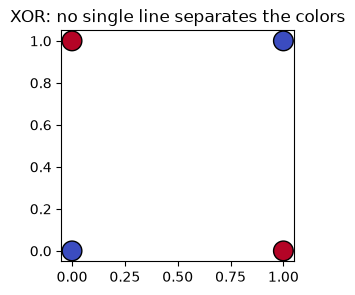

In [62]:
xor_x = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
xor_y = torch.tensor([0., 1., 1., 0.])

A = torch.cat([xor_x, torch.ones(4, 1)], dim=1)
print("선형 풀이의 예측:", A @ (torch.linalg.pinv(A) @ xor_y))

plt.figure(figsize=(3, 3))
plt.scatter(xor_x[:, 0], xor_x[:, 1], c=xor_y, cmap="coolwarm", s=200, edgecolors="k")
plt.title("XOR: no single line separates the colors")
plt.show()

모든 입력에 0.5라고 답합니다. 직선 하나로는 두 색을 나눌 수 없습니다. 이것이 **비선형** 문제입니다.

그러면 규칙은 어떻게 찾을까요? 비선형 규칙을 사람이 만들고 일부분만 기계에 맡길까요, 아니면 전부 맡길까요? 사람이 특징을 설계하면 머신러닝, 특징까지 모델이 찾으면 딥러닝입니다. ([ML vs DL 그림](https://i0.wp.com/semiengineering.com/wp-content/uploads/2018/01/MLvsDL.png?resize=733%2C405&ssl=1))

### 비선형성(nonlinearity)

선형 층은 아무리 쌓아도 수식이 전개되어 **층 하나와 같아집니다**.

$$W_2(W_1x) = (W_2W_1)x = Wx$$

> 성을 쌓아야 하는데 층을 나눠 주지 않으면 그냥 1층일 뿐입니다. 비선형 함수는 수식이 전개되지 않게 층을 나누어 표현력을 높여 줍니다.

참고: [비선형 설명](https://jjeongil.tistory.com/976) · [그림 1](https://blog.kakaocdn.net/dn/HT3Rp/btqBRvQm2dv/uywLIGEu9OwQ7Sq54hqpJ0/img.png) · [그림 2](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FtPvqQ%2FbtqBRvv4CEA%2F93ca1rPlaLKtA2Bzkfmrm0%2Fimg.png) · [딥러닝의 두 번의 겨울](https://datart.tistory.com/22) · [겨울 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FLi5pQ%2FbtqEInjvhOj%2F400k3ELodsXIOSENgzkkMk%2Fimg.png)

딥러닝이 항상 답은 아닙니다. 5부 끝의 당부를 기억해 주세요.

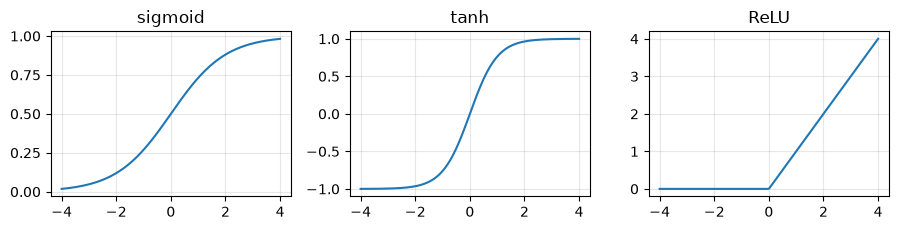

In [63]:
t = torch.linspace(-4, 4, 200)
fig, axes = plt.subplots(1, 3, figsize=(9, 2.4))
for ax, (name, fn) in zip(axes, [("sigmoid", torch.sigmoid), ("tanh", torch.tanh), ("ReLU", torch.relu)]):
    ax.plot(t, fn(t))
    ax.set_title(name)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3.3 수치적 접근(Numerical approach)

비선형 문제는 답을 식으로 바로 구하기 어렵습니다. 대신 **현재 위치의 기울기를 보고 조금씩 답에 다가갑니다**. ([수치해석 설명](http://www.aistudy.com/math/numerical_analysis.htm), [수치해 그림](https://i.ytimg.com/vi/32JSHu1yATM/maxresdefault.jpg))

그래서 기울기, 즉 미분이 핵심입니다. 먼저 미분을 추적하는 텐서부터 만들어 봅시다.

In [64]:
a = torch.ones((2, 2), requires_grad=True)
# 같은 표현: a = torch.ones((2, 2)); a.requires_grad = True
# 같은 표현: a = torch.ones((2, 2)); a.requires_grad_()   기본값이 True
print(a.requires_grad)

# 일반 텐서처럼 연산할 수 있다
b = torch.ones((2, 2), requires_grad=True)
print(a + b)
print(torch.add(a, b))

print(a * b)
print(torch.mul(a, b))

True
tensor([[2., 2.],
        [2., 2.]], grad_fn=<AddBackward0>)
tensor([[2., 2.],
        [2., 2.]], grad_fn=<AddBackward0>)
tensor([[1., 1.],
        [1., 1.]], grad_fn=<MulBackward0>)
tensor([[1., 1.],
        [1., 1.]], grad_fn=<MulBackward0>)


### Gradient 함수는 대체 무엇인가

다음 함수의 기울기를 계산한다고 합시다.

$$y_i = 5(x_i+1)^2$$

**Q. 어떻게 할 것인가요?**

In [65]:
x = torch.ones(2, requires_grad=True)
y = 5 * (x + 1) ** 2
print(x, y)

tensor([1., 1.], requires_grad=True) tensor([20., 20.], grad_fn=<MulBackward0>)


바로 `y.backward()`를 부르면 에러가 납니다.

`backward`는 **스칼라(원소 1개) 값**에서만 인자 없이 호출할 수 있습니다. 모델 파라미터에 대한 손실, 즉 스칼라 하나의 기울기를 구하도록 설계되었기 때문입니다. 원소가 여럿이면 어떤 값을 기준으로 미분할지 정해 주어야 합니다. (뒤의 야코비안 곱에서 다룹니다)

In [66]:
try:
    y.backward(retain_graph=True)     # y는 원소가 2개이므로 실패: 일부러 일으킨 에러
except RuntimeError as e:
    print("RuntimeError:", e)

RuntimeError: grad can be implicitly created only for scalar outputs


그렇다면 `y`를 스칼라로 바꿔 봅시다.

$$o = \frac{1}{2}\sum_i y_i$$

In [67]:
o = (1 / 2) * torch.sum(y)
print(o)

tensor(20., grad_fn=<MulBackward0>)


- 원래 공식: $y_i = 5(x_i+1)^2$
- 스칼라로 바꾼 결과: $o = \frac{1}{2}\sum_i y_i$
- $o$에 $y$를 집어넣으면: $o = \frac{1}{2} \sum_i 5(x_i+1)^2$

미분해 봅시다.

$$\frac{\partial o}{\partial x_i} = \frac{1}{2}[10(x_i+1)]$$

그러면 $x$가 1일 때 미분값은 다음과 같습니다.

$$\left.\frac{\partial o}{\partial x_i}\right|_{x_i=1} = \frac{1}{2}[10(1 + 1)] = \frac{10}{2}(2) = 10$$

미분을 아니까 수치적 업데이트를 할 수 있겠네요. **그런데 이 미분을 매번 내가 다 해야 하나요?** 아닙니다. 그것이 **autograd**입니다.

In [68]:
o.backward()       # 알아서 미분 수행
print(x.grad)      # 값은? 손계산과 같은 10
assert torch.equal(x.grad, torch.tensor([10., 10.]))

tensor([10., 10.])


그렇다면 다음과 같이 값을 수치적으로 업데이트할 수 있습니다. 미분값은 함숫값이 가장 빨리 커지는 방향이므로, 줄이려면 반대로 조금 움직입니다. 움직이는 정도가 **학습률(learning rate)** 입니다.

$$x \leftarrow x - \eta \frac{\partial o}{\partial x}$$

In [69]:
lr = 0.001
with torch.no_grad():        # 값을 고치는 연산은 미분 기록에서 제외
    x -= lr * x.grad
x.grad.zero_()               # grad 값을 0으로 만들어 줌(in-place)
print(x)

tensor([0.9900, 0.9900], requires_grad=True)


이 과정을 반복하면 어떻게 움직이는지 그려 봅시다. 또한 **미분값은 호출할 때마다 `.grad`에 누적**되므로, 위처럼 매번 지워야 합니다.

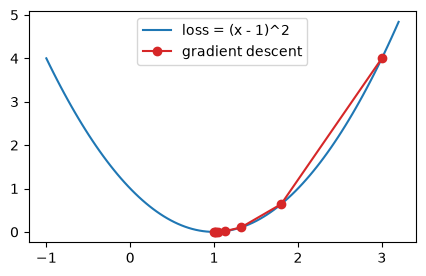

최종 x: 1.0013107061386108


In [70]:
x = torch.tensor([3.0], requires_grad=True)
path = []
for step in range(8):
    loss = (x - 1) ** 2           # x = 1에서 최소
    path.append((x.item(), loss.item()))
    loss.backward()
    with torch.no_grad():
        x -= 0.3 * x.grad
    x.grad.zero_()

curve = torch.linspace(-1, 3.2, 100)
plt.figure(figsize=(5, 3))
plt.plot(curve, (curve - 1) ** 2, label="loss = (x - 1)^2")
plt.plot(*zip(*path), "o-", color="tab:red", label="gradient descent")
plt.legend()
plt.show()
print("최종 x:", x.item())

In [71]:
# 지우지 않으면 어떻게 되는지 확인
x = torch.tensor([3.0], requires_grad=True)
for i in range(3):
    ((x - 1) ** 2).backward()
    print(f"{i + 1}번째 backward 후 grad =", x.grad.item())

1번째 backward 후 grad = 4.0
2번째 backward 후 grad = 8.0
3번째 backward 후 grad = 12.0


`x`가 `requires_grad`, 즉 기울기를 계산하기로 처음에 정의했으므로, 이후 연결된 `y`, `o`도 자동으로 기울기가 추적됩니다.

In [72]:
x = torch.ones(2, requires_grad=True)
y = 5 * (x + 1) ** 2
o = (1 / 2) * torch.sum(y)
print(x.requires_grad)
print(y.requires_grad)
print(o.requires_grad)
print((x ** 2).requires_grad)

True
True
True
True


## 3.4 추적이 필요 없다면? requires_grad, no_grad, zero_grad

([참고 글](https://nuguziii.github.io/dev/dev-003/))

| 도구 | 효과 |
|---|---|
| `requires_grad=False` | 이 파라미터는 업데이트하지 않음 |
| `torch.no_grad()` | 블록 안에서 기울기 계산 자체를 하지 않음 |
| `optimizer.zero_grad()` | 옵티마이저가 관리하는 모든 파라미터의 기울기를 지움 |
| `model.zero_grad()` | 모델의 모든 파라미터의 기울기를 지움. 하나의 모델에 옵티마이저가 여럿일 때 한 번에 지우는 용도 |

**Tip**: 기울기를 지워야 `backward`와 `step`이 제대로 동작합니다.

```python
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

자세한 활용은 5강 전이학습에서 다룹니다.

In [73]:
x = torch.tensor([1.], requires_grad=True)
with torch.no_grad():
    y = x * 2
print(y.requires_grad)

False


### Tip: 평가와 배포에서 이득 보는 법

모델을 평가할 때는 아래와 같이 `model.eval()`과 `torch.no_grad()`를 **함께** 씁니다.

```python
model.eval()
with torch.no_grad():
    for batch in data_loader:
        ...
```

- `model.eval()`: 학습 때만 필요한 dropout, batchnorm 등을 평가 동작으로 바꿉니다. **미분을 끄지는 않습니다.**
- `torch.no_grad()`: 구간 내 기울기 추적을 꺼서 메모리와 연산을 아낍니다. 평가 중 메모리가 계속 늘어나는 문제도 이것으로 막을 수 있습니다.

참고: [no_grad와 eval](https://yuevelyne.tistory.com/10)

## 3.5 잎 노드(leaf)와 requires_grad 상태 바꾸기

`requires_grad`는 다음과 같이 바꿀 수 있습니다.

```python
y.requires_grad_(False)   # in-place 형태
y.requires_grad = False   # 이렇게 지정해도 됨
```

그런데 연산 결과인 `y`에 하면 **에러**가 납니다. **잎 노드(leaf variable)** 만 바꿀 수 있기 때문입니다.

In [74]:
x = torch.tensor([1.], requires_grad=True)
y = x * 2

try:
    y.requires_grad_(False)       # 일부러 일으킨 에러
except RuntimeError as e:
    print("RuntimeError:", e)

# 잎 노드는 바꿀 수 있다
x.requires_grad_(False)
print(x.requires_grad)

# 연산 결과는 강제로 떼어 내야 한다. 단, 그래프가 끊긴다는 의미를 알고 써야 합니다
y = y.detach().clone()
y.requires_grad_(False)
print(y.requires_grad)

RuntimeError: you can only change requires_grad flags of leaf variables. If you want to use a computed variable in a subgraph that doesn't require differentiation use var_no_grad = var.detach().
False
False


### 다른 예제: 직접 만든 2층 신경망

$y = (x-2)^2$에 잡음을 더한 데이터를, 가중치를 직접 선언한 2층 신경망으로 근사합니다.

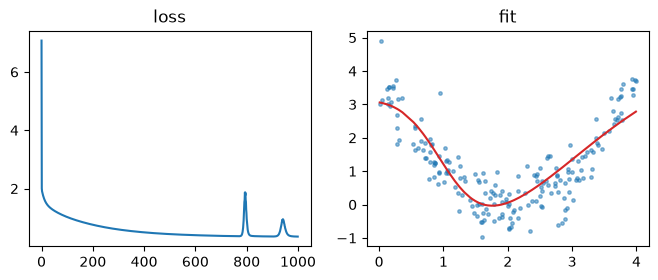

마지막 손실: 0.3527570068836212


In [75]:
set_seed()
x = torch.rand(200, 1) * 4
y = (x - 2) ** 2 + 0.5 * torch.randn(200, 1)      # 잡음의 분산은 0.25

weight1 = torch.randn(1, 10, requires_grad=True)
bias1 = torch.randn(10, requires_grad=True)
weight2 = torch.randn(10, 1, requires_grad=True)
bias2 = torch.randn(1, requires_grad=True)

lr = 0.1
loss_history = []
for step in range(1000):
    # 순전파
    linear = x @ weight1 + bias1
    hidden = torch.sigmoid(linear)
    prediction = hidden @ weight2 + bias2

    # 손실 계산과 역전파
    loss = ((prediction - y) ** 2).mean()
    loss.backward()
    loss_history.append(loss.item())

    # 가중치 갱신과 기울기 비우기
    for parameter in (weight1, bias1, weight2, bias2):
        parameter.data -= lr * parameter.grad
        parameter.grad = None

order = x.squeeze().argsort()
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
axes[0].plot(loss_history)
axes[0].set_title("loss")
axes[1].scatter(x, y, s=6, alpha=0.5)
axes[1].plot(x[order], prediction.detach()[order], color="tab:red")
axes[1].set_title("fit")
plt.show()
print("마지막 손실:", loss_history[-1])

마지막 손실은 잡음의 분산(0.25)보다 큽니다. 곡선이 아직 데이터를 다 따라가지 못했다는 뜻입니다. 손실 곡선에는 중간에 잠깐 튀는 구간도 보입니다. 학습률, 은닉 크기, 반복 횟수를 바꿔 어떻게 달라지는지 시험해 보세요.

**Q. 왜 `parameter -= lr * parameter.grad`가 아니라 `parameter.data -= lr * parameter.grad`로 썼을까요?**

<details><summary>답</summary>

`parameter`는 잎 노드이고 `requires_grad=True`입니다. 이런 텐서를 그래프 안에서 직접 in-place로 고치면 에러가 납니다. `.data`로 추적을 우회한 것입니다. 새 코드에서는 앞에서 쓴 `with torch.no_grad():`가 더 안전한 표현입니다. 아래에서 직접 확인합니다.
</details>

`weight1.is_leaf`가 `True`이면 계산 그래프의 잎 노드라는 뜻입니다.

- `requires_grad`가 `False`인 텐서는 보통 잎 텐서입니다.
- `requires_grad`가 `True`이고 사용자가 직접 만들었으면 잎 텐서입니다. 연산의 결과가 아니므로 `grad_fn`이 `None`입니다.
- `backward()` 시 `.grad`는 잎 텐서에만 채워집니다.
- 잎이 아닌 텐서의 `.grad`가 필요하면 `retain_grad()`를 부릅니다.

**생각해 볼 점**: 왜 중간 텐서의 `.grad`는 저장하지 않을까요? 메모리에 이득이 있기 때문입니다. ([포럼 토론](https://discuss.pytorch.org/t/what-is-the-purpose-of-is-leaf/87000/5))

In [76]:
try:
    weight1 -= lr * torch.ones_like(weight1)       # 일부러 일으킨 에러
except RuntimeError as e:
    print("RuntimeError:", e)

print("weight1.is_leaf:", weight1.is_leaf, "/ grad_fn:", weight1.grad_fn)
print("linear.is_leaf :", linear.is_leaf, "/ grad_fn:", linear.grad_fn)

# 중간 텐서의 grad를 보고 싶을 때
w = torch.rand(2, requires_grad=True)
mid = w * 3
mid.retain_grad()
mid.sum().backward()
print("mid.grad:", mid.grad)

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.
weight1.is_leaf: True / grad_fn: None
linear.is_leaf : False / grad_fn: <AddBackward0 object at 0x169a56710>
mid.grad: tensor([1., 1.])


In [77]:
learned = torch.rand(2, 3, requires_grad=True)
fixed_input = torch.rand(3, 2)
loss = ((learned @ fixed_input) ** 2).mean()
loss.backward()
print(learned.grad)
print(learned.is_leaf)
print(fixed_input.grad)      # requires_grad가 없으므로 None

tensor([[0.0598, 0.1135, 0.0848],
        [0.1171, 0.2517, 0.2496]])
True
None


다른 예제를 한번 봅시다. $\sum x^2$을 미분하면 얼마일까요?

In [78]:
x = torch.tensor([[1., -1.], [1., 1.]], requires_grad=True)
out = x.pow(2).sum()
out.backward()
print(x.grad)
assert torch.equal(x.grad, 2 * x.detach())   # 맞습니까? 2x와 같습니다

tensor([[ 2., -2.],
        [ 2.,  2.]])


## 3.6 (선택) 뉴턴-랩슨법(Newton-Raphson method)

자동 미분은 신경망 전용이 아닙니다. 접선을 그어 x축과 만나는 점으로 옮겨 가기를 반복하면 $f(x) = 0$의 해를 찾을 수 있습니다. ([설명 글](https://darkpgmr.tistory.com/58), [그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F012E143E517A0BBD36))

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}$$

$f(x) = e^x - 2 = 0$의 해는 $\ln 2 \approx 0.6931$입니다. 필요한 $f'(x)$를 autograd로 구해 봅시다.

1번째 반복: x = 3.03663
2번째 반복: x = 2.13262
3번째 반복: x = 1.36968
4번째 반복: x = 0.87805
5번째 반복: x = 0.70924
6번째 반복: x = 0.69328
7번째 반복: x = 0.69315
8번째 반복: x = 0.69315
움직임이 충분히 작아 멈춥니다
정답과의 차이: 1.904654323148236e-09


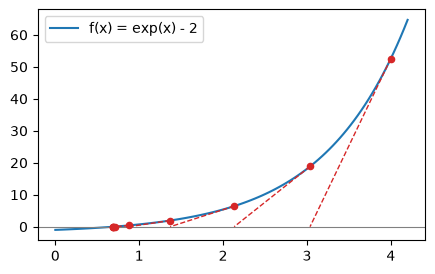

In [79]:
def exp_minus_two(value: torch.Tensor) -> torch.Tensor:
    """해를 찾고 싶은 함수입니다."""
    return torch.exp(value) - 2


def find_root(fn, start: float, max_steps: int = 10, tolerance: float = 1e-4) -> list:
    """뉴턴-랩슨법으로 해를 찾고, 거쳐 간 x 값들을 돌려줍니다."""
    guess = torch.tensor([start], requires_grad=True)
    visited = [start]
    for step in range(max_steps):
        value = fn(guess)
        value.backward()
        with torch.no_grad():
            move = value / guess.grad
            guess -= move
        guess.grad.zero_()         # 다음 반복은 새 위치의 기울기만 써야 한다
        visited.append(guess.item())
        print(f"{step + 1}번째 반복: x = {guess.item():.5f}")
        if abs(move.item()) < tolerance:
            print("움직임이 충분히 작아 멈춥니다")
            break
    return visited


visited = find_root(exp_minus_two, start=4.0)
print("정답과의 차이:", abs(visited[-1] - math.log(2)))

curve = torch.linspace(0, 4.2, 100)
plt.figure(figsize=(5, 3))
plt.plot(curve, torch.exp(curve) - 2, label="f(x) = exp(x) - 2")
plt.axhline(0, color="gray", lw=0.8)
for before, after in zip(visited, visited[1:]):
    plt.plot([before, after], [math.exp(before) - 2, 0], "--", color="tab:red", lw=1)
plt.scatter(visited, [math.exp(v) - 2 for v in visited], color="tab:red", zorder=3, s=20)
plt.legend()
plt.show()

## 3.7 연산 그래프를 코드로 따라가기

앞에서는 값 몇 개로 미분을 확인했습니다. 이번에는 아주 작은 분류 모델을 놓고, `backward()`가 무엇을 만들고 무엇을 채우는지 따라갑니다. 주제의 순서는 [PyTorch 한국어 튜토리얼의 autograd 편](https://tutorials.pytorch.kr/beginner/basics/autogradqs_tutorial.html)을 참고했으니, 같은 내용을 다른 설명으로 읽고 싶다면 함께 보세요.

모델은 입력 `x`에 가중치 `w`를 곱하고 편향 `b`를 더해 점수 `z`를 냅니다. 점수와 정답 `y`를 비교한 값이 손실입니다. 학습으로 고칠 값은 `w`와 `b`뿐이고, `x`와 `y`는 주어진 데이터입니다. 아래 그림의 화살표를 따라가 보세요. ([튜토리얼의 그림](https://tutorials.pytorch.kr/_images/comp-graph.png))

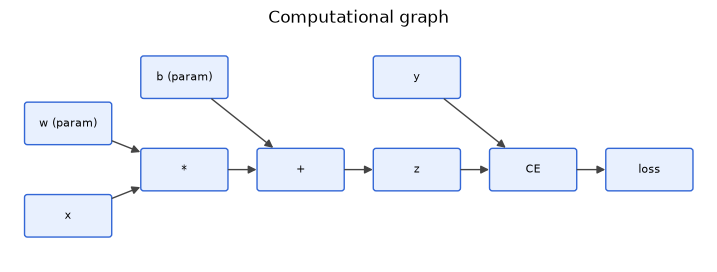

In [80]:
draw_flow(
    {"x": (0, 0, "x"), "w": (0, 1, "w (param)"), "mul": (1.2, 0.5, "*"), "b": (1.2, 1.5, "b (param)"),
     "add": (2.4, 0.5, "+"), "z": (3.6, 0.5, "z"), "ce": (4.8, 0.5, "CE"), "y": (3.6, 1.5, "y"), "loss": (6, 0.5, "loss")},
    [("x", "mul"), ("w", "mul"), ("mul", "add"), ("b", "add"), ("add", "z"), ("z", "ce"), ("y", "ce"), ("ce", "loss")],
    title="Computational graph",
)

`w`와 `b`에는 `requires_grad=True`를 켭니다. 이 값들에서 시작하는 계산을 기록해 두라는 표시입니다. 만들 때 켜도 되고, 나중에 `w.requires_grad_(True)`로 켜도 됩니다.

PyTorch는 연산을 실행할 때마다 결과 텐서에 "이 값을 거슬러 미분하는 방법"을 아는 객체를 붙입니다. 이 객체가 `grad_fn` 속성이고, 그래프의 마디(`torch.autograd.graph.Node`)입니다. 새로운 미분 규칙은 `Function` 클래스로 등록하며, 4부 단계 3에서 직접 만들어 봅니다. ([Function 문서](https://docs.pytorch.org/docs/stable/autograd.html#function))

### 기울기 계산하기

필요한 값은 $\frac{\partial loss}{\partial w}$와 $\frac{\partial loss}{\partial b}$입니다. `loss.backward()`를 한 번 부르면 `w.grad`와 `b.grad`에 들어옵니다.

정말 맞는지 손으로 유도한 식과 비교합시다. 손실로 쓴 `binary_cross_entropy_with_logits`는 2강에서 다시 만납니다. 여기서는 출력이 2개이고 $\sigma$가 sigmoid일 때 다음이 성립한다는 것만 쓰겠습니다.

$$\frac{\partial loss}{\partial z_j} = \frac{1}{2}\left(\sigma(z_j) - y_j\right)$$

$z_j = \sum_i x_i w_{ij} + b_j$이므로, 연쇄 법칙으로 $\frac{\partial loss}{\partial b_j}$는 위 값 그대로이고 $\frac{\partial loss}{\partial w_{ij}}$는 위 값에 $x_i$를 곱한 것입니다.

In [81]:
set_seed()
x = torch.tensor([0.5, -1.0, 2.0, 0.0])    # 입력 특징 4개
y = torch.tensor([1.0, 0.0])               # 출력 2개의 정답
w = torch.randn(4, 2, requires_grad=True)
b = torch.randn(2, requires_grad=True)

z = x @ w + b
loss = F.binary_cross_entropy_with_logits(z, y)
print("z의 grad_fn   :", z.grad_fn)
print("loss의 grad_fn:", loss.grad_fn)

loss.backward()
print("w.grad:", w.grad)
print("b.grad:", b.grad)

# 손으로 유도한 식과 비교한다
with torch.no_grad():
    dloss_dz = (torch.sigmoid(z) - y) / 2
assert torch.allclose(b.grad, dloss_dz)
assert torch.allclose(w.grad, torch.outer(x, dloss_dz))
print("손계산과 일치합니다")

z의 grad_fn   : <AddBackward0 object at 0x169b76470>
loss의 grad_fn: <BinaryCrossEntropyWithLogitsBackward0 object at 0x169b48e50>
w.grad: tensor([[-0.0335,  0.0093],
        [ 0.0670, -0.0185],
        [-0.1341,  0.0370],
        [ 0.0000,  0.0000]])
b.grad: tensor([-0.0670,  0.0185])
손계산과 일치합니다


위에서 두 가지 규칙을 기억하세요.

- `.grad`가 채워지는 곳은 `requires_grad=True`인 잎 노드입니다. 그래서 `w`, `b`에는 있고 중간 결과인 `z`에는 없습니다.
- 그래프는 메모리를 아끼려고 `backward` 한 번으로 해제됩니다. 같은 그래프로 또 미분하려면 `retain_graph=True`가 필요합니다. 이 절의 끝에서 확인합니다.

### 기록을 멈춰야 할 때

학습이 끝난 모델로 예측만 할 때는 미분할 일이 없으니 기록은 낭비입니다. 끄는 방법은 둘입니다. 구간 전체라면 `torch.no_grad()` 블록으로 감싸고, 텐서 하나를 떼어 내려면 `detach()`를 씁니다.

기록을 끄는 이유는 크게 두 가지입니다.

- 일부 파라미터를 고정(frozen)하고 나머지만 학습하려고 합니다. 5강의 전이학습에서 씁니다.
- 순전파만 할 때 계산과 메모리를 아낍니다.

In [82]:
z = x @ w + b
print("기본        :", z.requires_grad)

with torch.no_grad():
    print("no_grad 안  :", (x @ w + b).requires_grad)

print("detach 뒤   :", z.detach().requires_grad)

기본        : True
no_grad 안  : False
detach 뒤   : False


### 그래프는 언제 만들어지고 언제 쓰이나

autograd가 쌓는 기록은 방향이 있고 고리가 없는 그래프, **DAG(directed acyclic graph)** 입니다. 입력 쪽 텐서가 잎(leaf)이고, 마지막 결과(보통 손실)가 뿌리(root)입니다. 그래프의 마디가 앞에서 본 `grad_fn` 객체입니다.

| 시점 | autograd가 하는 일 |
|---|---|
| **순전파** | 연산을 계산하고, 결과에 `grad_fn`을 달아 그래프를 늘립니다 |
| **`backward()`** | 뿌리에서 출발해 `grad_fn`을 차례로 부르고, **연쇄 법칙**으로 곱해 가며 잎까지 내려갑니다. 결과는 잎의 `.grad`에 **더합니다** |

**그래프는 순전파를 할 때마다 새로 만들어집니다.** 미리 고정된 구조가 없으므로 `forward` 안에 `if`와 `for`를 써도 되고, 스텝마다 입력 크기가 달라도 됩니다. 4부 단계 7에서 직접 확인합니다.

### (선택) 출력이 스칼라가 아닐 때: 야코비안 곱

손실은 보통 숫자 하나지만, 출력이 여러 개일 때도 있습니다. 입력이 $n$개, 출력이 $m$개이면 가능한 편미분을 모두 모은 것은 $m \times n$ 행렬, **야코비안(Jacobian)** 입니다.

$$J=\begin{pmatrix} \frac{\partial y_{1}}{\partial x_{1}} & \cdots & \frac{\partial y_{1}}{\partial x_{n}}\\ \vdots & \ddots & \vdots\\ \frac{\partial y_{m}}{\partial x_{1}} & \cdots & \frac{\partial y_{m}}{\partial x_{n}} \end{pmatrix}$$

이 행렬을 통째로 만들면 비쌉니다. 그래서 `backward`는 출력별 가중치 $v$를 받아 $v^T J$만 계산합니다. $v$의 모양은 출력과 같아야 합니다.

아래에서 `out = inp ** 2`의 야코비안은 대각선이 $2 \cdot$`inp`인 대각 행렬입니다. `inp`가 `[1, 2, 3]`이고 $v$가 `[1, 0, 10]`이면 $v^T J$는 `[2, 0, 60]`입니다.

In [83]:
inp = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
out = inp ** 2
v = torch.tensor([1.0, 0.0, 10.0])

out.backward(v, retain_graph=True)
print("첫 번째 호출:", inp.grad)
assert torch.equal(inp.grad, torch.tensor([2.0, 0.0, 60.0]))

out.backward(v, retain_graph=True)
print("두 번째 호출:", inp.grad)

inp.grad.zero_()
out.backward(v)
print("지운 뒤 호출:", inp.grad)

첫 번째 호출: tensor([ 2.,  0., 60.])
두 번째 호출: tensor([  4.,   0., 120.])
지운 뒤 호출: tensor([ 2.,  0., 60.])


같은 인자로 두 번 부르니 값이 두 배가 되었습니다. `.grad`에 **더하기** 때문입니다. 학습에서 매번 기울기를 지우는 이유가 이것이고, 그 일을 옵티마이저의 `zero_grad()`가 해 줍니다.

> **참고**: 인자 없이 부르는 `backward()`는 $v$가 `torch.tensor(1.0)`인 경우입니다. 출력이 하나뿐이라 가중치를 고를 필요가 없습니다.

**autograd의 동작은 [공식 문서](https://docs.pytorch.org/docs/stable/notes/autograd.html)에 잘 정리되어 있으니 꼭 한 번 정독하세요.**

### `retain_graph=True`?

`backward()`는 메모리를 아끼려고, 계산을 마치면 **그래프의 중간 값을 해제**합니다. `retain_graph=True`는 다음 `backward`를 위해 그래프를 남겨 두라는 뜻입니다. ([참고 글](https://hongl.tistory.com/158), [참고 그림](https://blog.kakaocdn.net/dn/dvVY9X/btq4yks1geF/cP20M6nYBqeGOCms6PrNA1/img.png))

다른 코드에서 `torch.autograd.Variable`을 만나면 `requires_grad=True`인 텐서로 읽으면 됩니다. 새 코드에서는 쓸 필요가 없습니다.

In [84]:
param = torch.rand(1, 4, requires_grad=True)
doubled = (param ** 2) * 2
mean_loss = doubled.mean()
sum_loss = doubled.sum()

mean_loss.backward(retain_graph=True)   # 그래프를 남겨 둔다
sum_loss.backward()                     # 같은 그래프로 다시 미분할 수 있다. 이번에는 해제된다

try:
    doubled.sum().backward()            # 이미 해제되어 실패: 일부러 일으킨 에러
except RuntimeError as error:
    print("RuntimeError:", str(error)[:70], "...")

RuntimeError: Trying to backward through the graph a second time (or directly access ...


## 3.8 역전파(Backpropagation)

역전파는 **연쇄 법칙**을 출력에서 입력 쪽으로 적용하는 계산입니다. 거슬러 가며 미분을 곱해 갑니다.

손으로 계산해 봅시다. $x = 1$, $w_1 = 2$, $w_2 = 3$, 정답 $t = 10$일 때 다음과 같습니다.

$$h = w_1 x = 2, \quad a = h^2 = 4, \quad y = w_2 a = 12, \quad L = (y - t)^2 = 4$$

역방향으로 연쇄 법칙을 적용합니다.

$$\frac{\partial L}{\partial y} = 2(y-t) = 4, \qquad \frac{\partial L}{\partial w_2} = \frac{\partial L}{\partial y}\cdot a = 4 \cdot 4 = 16$$

$$\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial y}\cdot \frac{\partial y}{\partial a}\cdot \frac{\partial a}{\partial h}\cdot \frac{\partial h}{\partial w_1} = 4 \cdot w_2 \cdot 2h \cdot x = 4 \cdot 3 \cdot 4 \cdot 1 = 48$$

**반드시 공부하세요**: [역전파를 완벽하게 설명한 글](https://medium.com/@14prakash/back-propagation-is-very-simple-who-made-it-complicated-97b794c97e5c) · [한글 설명](https://wikidocs.net/60682) · 그림: [오차역전파](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F996805345B3AA2BA2D), [신경망 1](https://wikidocs.net/images/page/37406/nn1_final.PNG), [신경망 2](https://wikidocs.net/images/page/37406/nn2_final_final.PNG), [신경망 3](https://wikidocs.net/images/page/37406/nn3_final.PNG), [신경망 4](https://wikidocs.net/images/page/37406/nn4.PNG)

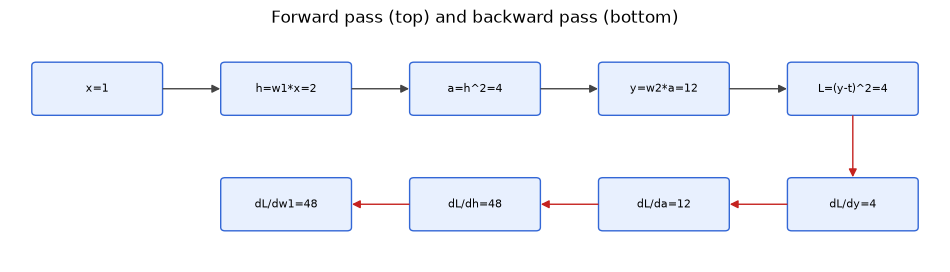

autograd: 48.0 16.0


In [85]:
draw_flow(
    {"x": (0, 0, "x=1"), "h": (1.3, 0, "h=w1*x=2"), "a": (2.6, 0, "a=h^2=4"), "y": (3.9, 0, "y=w2*a=12"), "L": (5.2, 0, "L=(y-t)^2=4"),
     "gL": (5.2, -1, "dL/dy=4"), "ga": (3.9, -1, "dL/da=12"), "gh": (2.6, -1, "dL/dh=48"), "gw": (1.3, -1, "dL/dw1=48")},
    [("x", "h"), ("h", "a"), ("a", "y"), ("y", "L"),
     ("L", "gL", "#c5221f"), ("gL", "ga", "#c5221f"), ("ga", "gh", "#c5221f"), ("gh", "gw", "#c5221f")],
    title="Forward pass (top) and backward pass (bottom)",
    size=(12, 3),
)

w1 = torch.tensor(2.0, requires_grad=True)
w2 = torch.tensor(3.0, requires_grad=True)
L = (w2 * (w1 * 1.0) ** 2 - 10) ** 2
L.backward()
print("autograd:", w1.grad.item(), w2.grad.item())
assert w1.grad == 48 and w2.grad == 16

**Q. 왜 이렇게 하는 걸까요?**

<details><summary>답</summary>

파라미터가 수백만 개여도, 역방향으로 **한 번만** 지나가면 손실에 대한 모든 파라미터의 미분을 구할 수 있습니다. 중간 결과를 재사용하기 때문입니다. 위 손계산에서 $\frac{\partial L}{\partial y}$를 $w_1$, $w_2$의 미분이 함께 쓰는 것이 그 예입니다.
</details>

### 실습 3

$f(w) = w^3 - 2w$일 때 $w = 2$에서의 미분값을 autograd로 구해 `grad_value`에 저장하세요. 손계산 값은 $3w^2 - 2 = 10$입니다.

In [86]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
w = torch.tensor(2.0, requires_grad=True)
f = w ** 3 - 2 * w
f.backward()
grad_value = w.grad.item()
assert grad_value == 10.0
print(grad_value)
```
</details>

---
# 4부. 코드 리뷰: 학습 코드의 진화

([참고 튜토리얼](https://docs.pytorch.org/tutorials/beginner/pytorch_with_examples.html#pytorch-control-flow-weight-sharing))

같은 문제를 도구를 하나씩 늘려 가며 다시 풉니다. 단계에 따라 주어진 코드를 해석해 보세요. **각 도구가 어떤 수고를 덜어 주는지** 보는 것이 목표입니다.

**문제**: $\sin(x)$를 3차 다항식으로 근사합니다.

```python
y_pred = a + b * x + c * x ** 2 + d * x ** 3
```

| 단계 | 미분 | 모델 | 가중치 갱신 |
|---|---|---|---|
| 1. 직접 구현 | 직접 유도 | 직접 작성 | 직접 작성 |
| 2. Autograd | **autograd** | 직접 작성 | 직접 작성 |
| 3. 사용자 정의 함수 | **미분 규칙을 직접 등록** | 직접 작성 | 직접 작성 |
| 4. `nn` | autograd | **`nn` 모듈** | 직접 작성 |
| 5. `optim` | autograd | `nn` 모듈 | **`optim`** |
| 6. 나만의 모듈 | autograd | **`nn.Module` 상속** | `optim` |
| 7. 제어 흐름 | autograd | **forward에 `for`, 가중치 공유** | `optim` |

## 단계 1. 직접 구현

손실 $L = \sum (\hat y - y)^2$를 각 계수로 미분한 식을 직접 코드로 옮깁니다. 모델이 복잡해지면 불가능한 방법입니다.

In [87]:
set_seed()
dtype = torch.float

# 입력과 출력 데이터
x = torch.linspace(-math.pi, math.pi, 2000, dtype=dtype)
y = torch.sin(x)

# 가중치를 무작위로 초기화
a = torch.randn((), dtype=dtype)
b = torch.randn((), dtype=dtype)
c = torch.randn((), dtype=dtype)
d = torch.randn((), dtype=dtype)

learning_rate = 1e-6
for t in range(2000):
    # 순전파: 예측값 계산
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    # 손실 계산 및 출력
    loss = (y_pred - y).pow(2).sum().item()
    if t % 100 == 99:
        print(t, loss)

    # 역전파: 손실에 대한 a, b, c, d의 기울기를 직접 계산
    grad_y_pred = 2.0 * (y_pred - y)
    grad_a = grad_y_pred.sum()
    grad_b = (grad_y_pred * x).sum()
    grad_c = (grad_y_pred * x ** 2).sum()
    grad_d = (grad_y_pred * x ** 3).sum()

    # 경사 하강법으로 가중치 갱신
    a -= learning_rate * grad_a
    b -= learning_rate * grad_b
    c -= learning_rate * grad_c
    d -= learning_rate * grad_d

print(f"Result: y = {a.item()} + {b.item()} x + {c.item()} x^2 + {d.item()} x^3")

99 1259.1181640625
199 857.206298828125
299 585.1223754882812
399 400.7316589355469
499 275.6364440917969
599 190.67608642578125
699 132.91024780273438
799 93.59030151367188
899 66.795654296875


999 48.51580047607422


1099 36.030555725097656
1199 27.49327850341797


1299 21.648799896240234


1399 17.643224716186523
1499 14.894838333129883


1599 13.006861686706543
1699 11.708498001098633
1799 10.814616203308105
1899 10.198519706726074
1999 9.773430824279785
Result: y = -0.02705521509051323 + 0.8398215770721436 x + 0.004667474422603846 x^2 + -0.09092377126216888 x^3


## 단계 2. Autograd를 이용하여 구현

미분식이 `loss.backward()` 한 줄로 바뀝니다. 같은 시드에서 시작하므로, 단계 1과 **손실값이 똑같이** 나오는지 확인하세요. autograd가 우리가 유도한 미분과 같은 값을 계산했다는 뜻입니다.

In [88]:
set_seed()
x = torch.linspace(-math.pi, math.pi, 2000, dtype=dtype)
y = torch.sin(x)

# requires_grad=True: 역전파 때 이 텐서들의 기울기를 계산하라는 표시.
# x, y는 기본값이 False이므로 기울기를 계산하지 않는다
a = torch.randn((), dtype=dtype, requires_grad=True)
b = torch.randn((), dtype=dtype, requires_grad=True)
c = torch.randn((), dtype=dtype, requires_grad=True)
d = torch.randn((), dtype=dtype, requires_grad=True)

learning_rate = 1e-6
for t in range(2000):
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    # 이제 loss는 텐서입니다. loss.item()으로 값을 꺼냅니다
    loss = (y_pred - y).pow(2).sum()
    if t % 100 == 99:
        print(t, loss.item())

    # requires_grad=True인 모든 텐서의 기울기를 계산해 .grad에 저장
    loss.backward()

    # 가중치는 추적이 필요 없으므로 no_grad 안에서 직접 갱신
    with torch.no_grad():
        a -= learning_rate * a.grad
        b -= learning_rate * b.grad
        c -= learning_rate * c.grad
        d -= learning_rate * d.grad

        # 옵티마이저를 쓰지 않아 zero_grad()를 부를 수 없으니 직접 지웁니다
        a.grad = None
        b.grad = None
        c.grad = None
        d.grad = None

print(f"Result: y = {a.item()} + {b.item()} x + {c.item()} x^2 + {d.item()} x^3")

99 1259.1181640625
199 857.206298828125
299 585.1223754882812
399 400.7316589355469
499 275.6364440917969
599 190.67608642578125
699 132.91024780273438
799 93.59030151367188
899 66.795654296875
999 48.51580047607422
1099 36.030555725097656
1199 27.49327850341797
1299 21.648799896240234
1399 17.643224716186523
1499 14.894838333129883


1599 13.006861686706543


1699 11.708498001098633


1799 10.814616203308105
1899 10.198519706726074
1999 9.773430824279785
Result: y = -0.02705521509051323 + 0.8398215770721436 x + 0.004667474422603846 x^2 + -0.09092377126216888 x^3


## 단계 3. (선택) 사용자 정의 autograd 함수

autograd가 모르는 연산이거나 미분을 직접 정의하고 싶다면, `Function`을 상속해 **순전파와 미분 규칙을 등록**할 수 있습니다.

위 다항식 모델을 조금 바꾸어 [르장드르 3차 다항식](https://en.wikipedia.org/wiki/Legendre_polynomials)을 적용해 봅시다.

- 기존: $y = a + bx + cx^2 + dx^3$
- 신규: $y = a + bP_3(c + dx)$, $\quad P_3(x) = \frac{1}{2}(5x^3 - 3x)$
- 미분: $P_3'(x) = \frac{3}{2}(5x^2 - 1)$

In [89]:
class LegendrePolynomial3(torch.autograd.Function):
    """torch.autograd.Function을 상속받아 순전파와 미분 규칙을 직접 정의합니다."""

    @staticmethod
    def forward(ctx, input: torch.Tensor) -> torch.Tensor:
        # ctx는 역전파 때 쓸 값을 보관하는 객체
        ctx.save_for_backward(input)
        return 0.5 * (5 * input ** 3 - 3 * input)

    @staticmethod
    def backward(ctx, grad_output: torch.Tensor) -> torch.Tensor:
        # 저장한 입력을 꺼내 손실에 대한 입력의 기울기를 계산
        input, = ctx.saved_tensors
        return grad_output * 1.5 * (5 * input ** 2 - 1)


x = torch.linspace(-math.pi, math.pi, 2000, dtype=dtype)
y = torch.sin(x)

# 수렴하도록 정답에서 너무 멀지 않은 값으로 초기화
a = torch.full((), 0.0, dtype=dtype, requires_grad=True)
b = torch.full((), -1.0, dtype=dtype, requires_grad=True)
c = torch.full((), 0.0, dtype=dtype, requires_grad=True)
d = torch.full((), 0.3, dtype=dtype, requires_grad=True)

learning_rate = 5e-6
for t in range(2000):
    # Function은 apply로 호출합니다
    P3 = LegendrePolynomial3.apply

    y_pred = a + b * P3(c + d * x)

    loss = (y_pred - y).pow(2).sum()
    if t % 100 == 99:
        print(t, loss.item())

    loss.backward()

    with torch.no_grad():
        a -= learning_rate * a.grad
        b -= learning_rate * b.grad
        c -= learning_rate * c.grad
        d -= learning_rate * d.grad

        a.grad = None
        b.grad = None
        c.grad = None
        d.grad = None

print(f"Result: y = {a.item()} + {b.item()} * P3({c.item()} + {d.item()} x)")

99 209.9583282470703
199 144.66018676757812
299 100.70249938964844
399 71.03519439697266
499 50.97850799560547
599 37.403133392333984
699 28.206863403320312
799 21.97318458557129


899 17.7457275390625


999 14.877889633178711
1099 12.931766510009766
1199 11.610919952392578
1299 10.71425724029541


1399 10.10548210144043


1499 9.692106246948242


1599 9.411376953125
1699 9.220746040344238
1799 9.091286659240723
1899 9.003362655639648


1999 8.943642616271973
Result: y = -7.662701029254038e-10 + -2.208526849746704 * P3(-3.5891992156145136e-10 + 0.2554861009120941 x)


## 단계 4. `nn` 모듈을 활용

입력을 $(x, x^2, x^3)$ 세 개로 만들면, 다항식은 입력 3개짜리 선형층 하나와 같습니다. 가중치 관리를 `nn`에 맡깁니다.

In [90]:
set_seed()
x = torch.linspace(-math.pi, math.pi, 2000)
y = torch.sin(x)

p = torch.tensor([1, 2, 3])
xx = x.unsqueeze(-1).pow(p)     # (2000, 3)

model = torch.nn.Sequential(
    torch.nn.Linear(3, 1),
    torch.nn.Flatten(0, 1),
)

loss_fn = torch.nn.MSELoss(reduction="sum")

learning_rate = 1e-6
for t in range(2000):
    y_pred = model(xx)

    loss = loss_fn(y_pred, y)
    if t % 100 == 99:
        print(t, loss.item())

    # 역전파 전에 기울기를 지움
    model.zero_grad()

    loss.backward()

    with torch.no_grad():
        for param in model.parameters():
            param -= learning_rate * param.grad

linear_layer = model[0]

# 선형층의 파라미터는 weight와 bias에 저장되어 있다
print(f"Result: y = {linear_layer.bias.item()} + {linear_layer.weight[:, 0].item()} x + {linear_layer.weight[:, 1].item()} x^2 + {linear_layer.weight[:, 2].item()} x^3")

99 887.6953735351562
199 596.037353515625
299 401.4063415527344
399 271.45233154296875
499 184.63290405273438
599 126.59546661376953
699 87.77372741699219
799 61.788475036621094
899 44.38311004638672
999 32.71636962890625
1099 24.890287399291992


1199 19.63644027709961


1299 16.10650062561035


1399 13.732831954956055
1499 12.135294914245605
1599 11.059157371520996
1699 10.333560943603516


1799 9.84384536743164
1899 9.513021469116211
1999 9.289302825927734
Result: y = -0.01432199776172638 + 0.8402137160301208 x + 0.0024707838892936707 x^2 + -0.09097954630851746 x^3


## 단계 5. `optim`도 사용

갱신 규칙까지 맡기면, 모든 PyTorch 학습 코드의 뼈대인 **세 줄**이 완성됩니다.

```python
optimizer.zero_grad()   # 1. 이전 미분값 지우기
loss.backward()         # 2. 미분 계산
optimizer.step()        # 3. 가중치 갱신
```

In [91]:
set_seed()
model = torch.nn.Sequential(
    torch.nn.Linear(3, 1),
    torch.nn.Flatten(0, 1),
)
loss_fn = torch.nn.MSELoss(reduction="sum")

learning_rate = 1e-3
optimizer = torch.optim.RMSprop(model.parameters(), lr=learning_rate)
for t in range(2000):
    y_pred = model(xx)

    loss = loss_fn(y_pred, y)
    if t % 100 == 99:
        print(t, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

linear_layer = model[0]
print(f"Result: y = {linear_layer.bias.item()} + {linear_layer.weight[:, 0].item()} x + {linear_layer.weight[:, 1].item()} x^2 + {linear_layer.weight[:, 2].item()} x^3")

99 3327.52294921875
199 1038.0146484375
299 728.9307861328125
399 645.4993286132812


499 553.9405517578125
599 452.68560791015625
699 352.0718688964844
799 260.80181884765625


899 183.29434204101562


999 121.20115661621094


1099 74.53498840332031
1199 42.258541107177734
1299 22.592689514160156


1399 12.896459579467773
1499 9.536417961120605


1599 8.943592071533203
1699 8.87311840057373
1799 8.886918067932129
1899 8.928772926330566
1999 8.934850692749023
Result: y = -0.0004848087555728853 + 0.8562273979187012 x + -0.000484899734146893 x^2 + -0.09387006610631943 x^3


## 단계 6. 나만의 `nn.Module`

직접 설계한 모델은 `nn.Module`을 상속해 만듭니다. `__init__`에서 부품을 준비하고 `forward`에서 계산을 정의합니다.

In [92]:
class Polynomial3(torch.nn.Module):
    def __init__(self):
        """네 개의 파라미터를 만들어 멤버로 등록합니다."""
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """입력 텐서를 받아 출력 텐서를 돌려줍니다. 임의의 연산을 쓸 수 있습니다."""
        return self.a + self.b * x + self.c * x ** 2 + self.d * x ** 3

    def string(self) -> str:
        """일반 파이썬 클래스처럼 원하는 메서드를 추가할 수 있습니다."""
        return f"y = {self.a.item()} + {self.b.item()} x + {self.c.item()} x^2 + {self.d.item()} x^3"


set_seed()
model = Polynomial3()

# model.parameters()에는 위에서 등록한 학습 가능한 파라미터가 들어 있다
criterion = torch.nn.MSELoss(reduction="sum")
optimizer = torch.optim.SGD(model.parameters(), lr=1e-6)
for t in range(2000):
    y_pred = model(x)

    loss = criterion(y_pred, y)
    if t % 100 == 99:
        print(t, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Result: {model.string()}")

99 1259.1181640625
199 857.206298828125
299 585.1224365234375


399 400.7316589355469


499

 275.6364440917969
599 190.6761474609375
699 132.91026306152344
799 93.59032440185547


899 66.79568481445312
999 48.515811920166016
1099 36.03056716918945
1199 27.493289947509766
1299 21.648799896240234


1399 17.643224716186523
1499 14.8948392868042
1599 13.006861686706543
1699 11.708498001098633
1799 10.814617156982422


1899 10.198521614074707
1999 9.773430824279785
Result: y = -0.02705521509051323 + 0.8398215770721436 x + 0.004667474422603846 x^2 + -0.09092377126216888 x^3


## 단계 7. 제어 흐름과 가중치 공유

실행할 때마다 그래프가 새로 만들어지므로 `forward` 안에서 일반 파이썬 제어문을 쓸 수 있습니다. 아래 모델은 호출할 때마다 항의 개수가 무작위로 바뀌고, 파라미터 `e`를 여러 항이 함께 씁니다(가중치 공유).

이 모델은 학습이 까다로워 학습률을 아주 작게 잡고 momentum을 쓰며, 30000 스텝을 돕니다.

In [93]:
class DynamicNet(torch.nn.Module):
    def __init__(self):
        """다섯 개의 파라미터를 만들어 멤버로 등록합니다."""
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))
        self.e = torch.nn.Parameter(torch.randn(()))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """호출마다 4차항, 5차항을 무작위로 더합니다. 같은 파라미터 e를 재사용해도 안전합니다."""
        y = self.a + self.b * x + self.c * x ** 2 + self.d * x ** 3
        for exp in range(4, random.randint(4, 6)):
            y = y + self.e * x ** exp
        return y

    def string(self) -> str:
        return f"y = {self.a.item()} + {self.b.item()} x + {self.c.item()} x^2 + {self.d.item()} x^3 + {self.e.item()} x^4 ? + {self.e.item()} x^5 ?"


set_seed()
model = DynamicNet()

criterion = torch.nn.MSELoss(reduction="sum")
optimizer = torch.optim.SGD(model.parameters(), lr=1e-8, momentum=0.9)
for t in range(30000):
    y_pred = model(x)

    loss = criterion(y_pred, y)
    if t % 2000 == 1999:
        print(t, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Result: {model.string()}")

1999 803.0394287109375


3999 385.782470703125


5999 199.56808471679688


7999 95.53424072265625


9999 51.31558609008789


11999 28.563974380493164


... (5 outputs left out)

23999 8.861659049987793


25999 8.96211051940918


27999 8.694120407104492


29999 8.608747482299805
Result: y = -0.004562541842460632 + 0.8551012277603149 x + 0.0002737180329859257 x^2 + -0.09342712163925171 x^3 + 0.00013731348735745996 x^4 ? + 0.00013731348735745996 x^5 ?


## 다시 XOR: 비선형으로 풀기

선형 풀이로는 모두 0.5밖에 답하지 못했던 XOR입니다. 비선형 함수(`ReLU`)를 낀 2층 모델로 다시 풀어 봅니다.

In [94]:
set_seed()
xor_model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1))
optimizer = torch.optim.Adam(xor_model.parameters(), lr=0.05)

for step in range(500):
    loss = F.binary_cross_entropy_with_logits(xor_model(xor_x).squeeze(dim=1), xor_y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    probs = torch.sigmoid(xor_model(xor_x)).squeeze(dim=1)
print("예측 확률:", probs.round(decimals=3))
print("정답     :", xor_y)
assert torch.equal(probs.round(), xor_y)

예측 확률: tensor([0., 1., 1., 0.])
정답     : tensor([0., 1., 1., 0.])


### 실습 4

`nn.Linear`를 두 번 쓰고 사이에 `nn.Tanh()`를 넣은 모델로 `sin` 함수를 근사하세요. 은닉 크기는 32, 옵티마이저는 `Adam(lr=0.01)`, 손실은 `nn.MSELoss()`, 1000 스텝 학습 후 마지막 손실을 `final_loss`에 저장합니다. 입력은 `x.unsqueeze(1)`, 정답은 `y.unsqueeze(1)`로 모양을 맞추세요.

In [95]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
set_seed()
net = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 1))
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
criterion = nn.MSELoss()
inputs, targets = x.unsqueeze(1), y.unsqueeze(1)
for step in range(1000):
    loss = criterion(net(inputs), targets)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
final_loss = loss.item()
assert final_loss < 0.05
print(final_loss)
```
</details>

---
# 5부. 첫 이미지 분류기

## 5.1 PyTorch 모델

PyTorch는 앞의 역전파, 즉 연쇄 미분을 그래프 기반으로 자동 수행하는 라이브러리입니다. 이제 실제 모델을 어떻게 표현하는지 알아봅시다.

### 모델 학습의 전체 절차

학습을 실행하면 다음 단계가 일어납니다. 이 강의 코드가 이 과정대로 가는지 살펴보세요.

1. **모델 정의**: `nn.Module`을 상속합니다. `__init__`에서 계층을 초기화하고 `forward`에서 순전파 연산을 정의합니다.
2. **미니배치 데이터 로딩**: 학습 데이터셋을 작은 그룹으로 나누어 가져옵니다. GPU와 병렬 처리를 효율적으로 쓸 수 있습니다.
3. **순전파(Forward Pass)**: 미니배치를 모델에 넣어 예측합니다.
4. **손실 계산**: 예측과 정답의 차이를 평균 제곱 오차, 교차 엔트로피 같은 손실 함수로 계산합니다.
5. **역전파(Backpropagation)**: 손실을 매개변수로 미분해 기울기를 구합니다.
6. **옵티마이저 업데이트**: 기울기로 가중치와 편향을 조정합니다.
7. **학습 과정 모니터링**: 손실, 정확도 같은 지표를 기록합니다.
8. **에폭 반복**: 정해진 횟수만큼 또는 중지 조건까지 반복합니다. 에폭이란 전체 학습 데이터를 한 번 순회하는 것입니다.
9. **모델 저장**: 가중치와 설정을 저장해 재사용합니다.
10. **평가 또는 테스트**: 검증 또는 테스트 데이터로 일반화 성능을 평가합니다.
11. **추론 및 예측**: 학습된 모델로 새 데이터를 예측합니다.

### LeNet-5

LeNet-5는 초기 합성곱 신경망 중 하나로, 손으로 쓴 숫자 이미지(MNIST)를 분류하기 위해 제작되었습니다. ([구조 그림](https://velog.velcdn.com/images/choonsik_mom/post/ca2d73df-2ed0-4d4f-bb75-d1e0f33a214b/image.png))

합성곱과 풀링은 3강에서 자세히 다루니, 여기서는 **텐서 모양이 어떻게 바뀌는지**만 따라가세요. LeNet-5의 동작을 코드로 옮기면 어떻게 될까요?

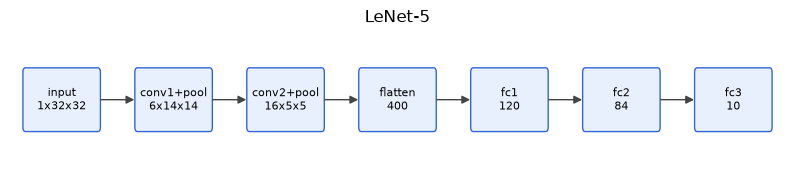

In [96]:
draw_flow(
    {"in": (0, 0, "input\n1x32x32"), "c1": (1.3, 0, "conv1+pool\n6x14x14"), "c2": (2.6, 0, "conv2+pool\n16x5x5"),
     "fl": (3.9, 0, "flatten\n400"), "f1": (5.2, 0, "fc1\n120"), "f2": (6.5, 0, "fc2\n84"), "f3": (7.8, 0, "fc3\n10")},
    [("in", "c1"), ("c1", "c2"), ("c2", "fl"), ("fl", "f1"), ("f1", "f2"), ("f2", "f3")],
    title="LeNet-5",
    size=(10, 1.8),
)

In [97]:
class LeNet(nn.Module):

    def __init__(self):
        super().__init__()
        # 입력 1채널, 출력 6채널, 5x5 합성곱 커널
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        # 아핀 변환: y = Wx + b
        self.fc1 = nn.Linear(16 * 5 * 5, 120)    # 5x5는 합성곱을 거친 이미지 크기
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # 최대 풀링은 (2, 2) 윈도우 크기를 사용
        x = F.max_pool2d(F.relu(self.conv1(x)), (2, 2))
        # 크기가 정방이면 숫자 하나로 지정할 수 있음
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = x.view(-1, self.num_flat_features(x))
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

    def num_flat_features(self, x: torch.Tensor) -> int:
        """1차원으로 폈을 때의 길이를 계산합니다. torch.flatten을 쓰면 더 간단합니다."""
        size = x.size()[1:]     # 배치 차원을 제외한 모든 차원
        num_features = 1
        for s in size:
            num_features *= s
        return num_features

코드를 살펴보면 구조적으로 위 그림과 비슷합니다. 일반적인 PyTorch 모델의 구조는 다음과 같습니다.

- 모듈은 중첩될 수 있으며 `torch.nn.Module`을 상속합니다. 실제로 `Conv2d`와 `Linear`도 `torch.nn.Module`을 상속합니다.
- 모델은 계층을 만들고 필요한 데이터를 불러오는 `__init__()`을 가집니다. 예를 들어 NLP 모델은 어휘를 불러올 수 있습니다.
- 모델은 실제 계산을 수행하는 `forward()`를 가집니다. 입력이 계층과 함수를 통과해 결과를 만듭니다.
- 그 외에는 일반 파이썬 클래스처럼 속성과 메서드를 추가할 수 있습니다.

### 다른 구현 비교

같은 LeNet-5를 층을 묶어 다르게 적은 구현입니다. ([참고 글](https://deep-learning-study.tistory.com/503)) **어떤 구현이 마음에 드시나요?**

In [98]:
class LeNetPaper(nn.Module):
    """논문처럼 tanh와 평균 풀링을 쓰고, 특징 추출과 분류를 나누어 묶은 구현입니다."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(16, 120, 5), nn.Tanh(),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        scores = self.classifier(self.features(x))
        return F.softmax(scores, dim=1)


paper_model = LeNetPaper()
print(paper_model)
print(paper_model(torch.rand(2, 1, 32, 32)).sum(dim=1))    # softmax이므로 합이 1

LeNetPaper(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): Tanh()
    (3): Linear(in_features=84, out_features=10, bias=True)
  )
)
tensor([1., 1.], grad_fn=<SumBackward1>)


> 차이를 눈여겨보세요. 이 구현은 논문처럼 `tanh`와 평균 풀링을 쓰고, 마지막에 `softmax`를 적용합니다. 뒤에서 쓸 `nn.CrossEntropyLoss`는 내부에 softmax를 포함하므로, 이 손실로 학습할 모델은 앞의 `LeNet`처럼 softmax 없이 값을 그대로 돌려줘야 합니다.

### 모델 동작 테스트

- 모델 인스턴스를 만듭니다.
- 입력 데이터를 만듭니다.
- `forward`를 실행합니다.

In [99]:
net = LeNet()
print(net)                         # 객체를 출력하면 구조를 보여 줍니다

input = torch.rand(1, 1, 32, 32)   # 32x32 크기의 1채널 흑백 이미지
print("\n이미지 배치 shape:")
print(input.shape)

output = net(input)                # forward()를 직접 부르지 않고 객체를 호출합니다
print("\n결과 값:")
print(output)
print(output.shape)

LeNet(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

이미지 배치 shape:
torch.Size([1, 1, 32, 32])

결과 값:
tensor([[ 0.0428, -0.0470, -0.0954, -0.0280,  0.0323,  0.0283, -0.0482, -0.0635,
          0.1066, -0.1064]], grad_fn=<AddmmBackward0>)
torch.Size([1, 10])


위에서 몇 가지 중요한 일이 일어납니다.

첫째, `LeNet` 클래스로 `net` 객체를 만들어 출력하면 `nn.Module`의 하위 클래스가 층의 구성을 알려 줍니다.

둘째, 1채널 `32x32` 이미지 크기의 더미 입력을 만듭니다. 실제로는 이미지를 읽어 같은 크기의 텐서로 변환합니다.

셋째, 텐서의 추가 차원인 **배치 차원**에 주목하세요. PyTorch 모델은 데이터의 **배치**에 작업한다고 가정합니다. 예를 들어 16개 이미지의 배치는 `(16, 1, 32, 32)` 모양입니다. 여기서는 한 장만 쓰므로 `(1, 1, 32, 32)`입니다.

넷째, 모델을 함수처럼 `net(input)`으로 호출해 추론합니다. 결과는 입력 이미지가 각 숫자일 신뢰도를 나타내는 점수입니다. 아직 학습 전이므로 좋은 결과를 기대하면 안 됩니다. 출력도 배치 차원을 가집니다. 입력이 16개면 출력은 `(16, 10)`입니다.

In [100]:
print(net(torch.rand(16, 1, 32, 32)).shape)

torch.Size([16, 10])


## 5.2 Dataset과 DataLoader

- **`Dataset`**: 데이터를 모아 놓은 것입니다. 데이터 **한 개**를 꺼내는 방법을 압니다.
- **`DataLoader`**: 이 데이터를 긁어 오는 에이전트입니다. **배치로 묶고**, 섞고, 병렬로 읽습니다.

PyTorch의 `Dataset`에는 TorchVision, TorchAudio 등의 내려받기 가능한 데이터셋뿐 아니라, 레이블된 이미지 폴더를 읽는 `torchvision.datasets.ImageFolder` 같은 도구도 있습니다. `Dataset`의 하위 클래스를 직접 만들 수도 있습니다. `__len__`과 `__getitem__`만 구현하면 됩니다.

In [101]:
class SquareDataset(Dataset):
    """숫자 x와 x의 제곱을 돌려주는 연습용 데이터셋입니다."""

    def __init__(self, size: int):
        self.x = torch.arange(size, dtype=torch.float32)

    def __len__(self) -> int:
        return len(self.x)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.x[idx], self.x[idx] ** 2

set_seed()
dataset = SquareDataset(10)
print("개수:", len(dataset), "/ 3번째 데이터:", dataset[3])

for xb, yb in DataLoader(dataset, batch_size=4, shuffle=True):
    print(xb.tolist(), yb.tolist())   # 마지막 배치는 2개만 남는다

개수: 10 / 3번째 데이터: (tensor(3.), tensor(9.))
[1.0, 0.0, 4.0, 9.0] [1.0, 0.0, 16.0, 81.0]
[2.0, 7.0, 5.0, 3.0] [4.0, 49.0, 25.0, 9.0]
[8.0, 6.0] [64.0, 36.0]


### 공개 데이터셋: CIFAR-10

TorchVision에서 바로 내려받을 수 있는 공개 데이터셋을 씁니다. 첫 번째 할 일은 들어오는 이미지를 PyTorch 텐서로 변환하는 것입니다.

- `v2.ToImage()`: 이미지를 `CHW` 텐서로 바꿉니다.
- `v2.ToDtype(torch.float32, scale=True)`: 실수로 바꾸고 값의 범위를 `[0, 1]`로 맞춥니다. 다른 코드에서 자주 보이는 `transforms.ToTensor()`는 이 두 단계를 합친 것으로, `v2`에서는 폐기 예정입니다.
- `v2.Normalize(mean, std)`: $(x - \text{mean}) / \text{std}$를 계산합니다. 평균과 표준편차를 모두 0.5로 주면 값의 범위가 `[-1, 1]`이 됩니다. 대부분의 활성화 함수는 0 근처의 기울기가 크므로, 데이터를 0 주변으로 모으면 학습이 빨라집니다.

`torchvision.transforms.v2`는 자르기, 회전, 뒤집기 등 더 많은 변환을 지원합니다.

**CIFAR-10**은 동물 6종(새, 고양이, 사슴, 개, 개구리, 말)과 차량 4종(비행기, 자동차, 배, 트럭)으로 이루어진 `32x32` 컬러 이미지 데이터셋입니다.

데이터셋을 만들 때 지정하는 값은 다음과 같습니다.

- `root`: 데이터를 저장할 경로
- `train`: 학습용인지 테스트용인지
- `download`: 없으면 내려받을지
- `transform`: 데이터에 적용할 변환

> 아래 셀은 처음 실행할 때 내려받느라 시간이 걸릴 수 있습니다.

In [102]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

trainset = torchvision.datasets.CIFAR10(root="./data", train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root="./data", train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=4,
                                         shuffle=False, num_workers=2)

classes = ("plane", "car", "bird", "cat",
           "deer", "dog", "frog", "horse", "ship", "truck")

`Dataset` 하위 클래스는 데이터에 접근하는 방법을 담고 있습니다. `DataLoader`는 데이터의 내용을 전혀 모르며, `Dataset`이 주는 텐서를 지정한 설정대로 묶어 줍니다.

위 예제의 `DataLoader`는 `trainset`에서 무작위(`shuffle=True`)로 이미지 4장씩 배치를 만들고, 데이터를 읽기 위해 일꾼 2개(`num_workers=2`)를 띄웁니다. `DataLoader`는 **반복 가능(iterable)** 하게 동작하며 데이터를 줍니다. `DataLoader`가 주는 배치를 시각화해 보는 것은 좋은 연습입니다. 아래 셀을 실행하면 사진 4장과 라벨을 볼 수 있습니다. 공개본에는 사진을 저장하지 않았습니다.

In [103]:
def imshow(img: torch.Tensor) -> None:
    """정규화된 이미지를 되돌려 화면에 보여 줍니다."""
    img = img / 2 + 0.5     # 역정규화
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))     # CHW -> HWC
    plt.axis("off")
    plt.show()


# 무작위로 학습 이미지 가져오기
dataiter = iter(trainloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))
print(" ".join(f"{classes[labels[j]]:5s}" for j in range(4)))

bird  bird  car   deer 


이 셀의 그림은 제3자 데이터의 사진이 보여 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


### DataLoader의 재현성

`shuffle=True`의 순서도 난수입니다. 전용 생성기(`generator`)를 넘기면 다른 코드가 난수를 얼마나 썼는지와 상관없이 같은 순서가 나옵니다.

In [104]:
def first_batch(seed: int) -> list:
    """전용 생성기로 섞었을 때의 첫 배치를 돌려줍니다."""
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(dataset, batch_size=4, shuffle=True, generator=generator)
    return next(iter(loader))[0].tolist()

print("시드 0:", first_batch(0))
print("시드 0:", first_batch(0))
print("시드 1:", first_batch(1))
assert first_batch(0) == first_batch(0)

시드 0: [3.0, 7.0, 5.0, 2.0]
시드 0: [3.0, 7.0, 5.0, 2.0]
시드 1: [4.0, 6.0, 9.0, 2.0]


일꾼을 쓸 때(`num_workers > 0`)는 일꾼 프로세스의 파이썬, NumPy 난수도 맞춰 줍니다. 공식 문서의 방법은 다음과 같습니다. ([공식 문서](https://docs.pytorch.org/docs/stable/notes/randomness.html#dataloader))

```python
def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

generator = torch.Generator().manual_seed(0)
loader = DataLoader(trainset, batch_size=4, shuffle=True, num_workers=2,
                    worker_init_fn=seed_worker, generator=generator)
```

> **주의**: 위 코드를 Mac의 Jupyter에서 실행하면 일꾼이 `seed_worker`를 찾지 못해 `DataLoader worker exited unexpectedly` 에러가 납니다. 일꾼을 새 프로세스로 띄우는 방식(spawn) 때문입니다. 이때는 함수를 `.py` 파일로 옮겨 불러오세요. 그래서 위 코드 블록은 실행 셀로 두지 않았습니다.

## 5.3 PyTorch 모델 학습

위에서 다룬 내용들을 종합해 모델을 학습시키겠습니다.

### 모델 만들기

CIFAR-10은 3채널이므로 입력 채널을 3으로 합니다.

In [105]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


set_seed()
net = Net().to(device)
print(net)
print("파라미터 수:", sum(p.numel() for p in net.parameters()))

Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
파라미터 수: 62006


**Q. 이 모델의 이름은 무엇일까요?**

<details><summary>답</summary>

입력 채널만 3으로 바꾼 **LeNet**입니다. 앞의 `LeNet`과 표현 방식만 다릅니다. 풀링을 층(`nn.MaxPool2d`)으로 만들었는지, 함수(`F.max_pool2d`)로 불렀는지의 차이입니다.
</details>

학습에 필요한 **기준**과 **방법**을 마련합니다.

**손실 함수(loss function)** 는 모델의 예측이 정답과 얼마나 차이 나는지를 나타내는 지표입니다. Cross-entropy 손실 함수는 분류 모델의 전형적인 손실 함수입니다.

**옵티마이저(optimizer)** 는 학습의 필수 요소입니다. 여기서는 간단한 **확률적 경사 하강법(SGD)** 을 씁니다. 학습률(`lr`), momentum 같은 설정과 함께, 학습할 모델의 모든 가중치 `net.parameters()`를 전달합니다.

In [106]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

마지막으로, 모든 것이 학습 루프에 들어갑니다. 실행에 몇 분 걸릴 수 있습니다.

In [107]:
for epoch in range(2):    # 데이터셋을 여러 번 반복 학습
    net.train()
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # 이미지와 정답을 받아 모델과 같은 장치로 옮김
        inputs, labels = data[0].to(device), data[1].to(device)

        # 기울기를 0으로 지움
        optimizer.zero_grad()

        # 순전파 + 역전파 + 최적화
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # epoch과 손실값 출력
        running_loss += loss.item()
        if i % 2000 == 1999:    # 2000 미니배치마다 출력
            print(f"[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}")
            running_loss = 0.0

print("Finished Training")

[1,  2000] loss: 2.204


[1,  4000] loss: 1.915


[1,  6000] loss: 1.709


[1,  8000] loss: 1.613


[1, 10000] loss: 1.517


[1, 12000] loss: 1.470


... (3 outputs left out)

[2,  8000] loss: 1.351


[2, 10000] loss: 1.324


[2, 12000] loss: 1.307


Finished Training


코드를 뜯어봅시다.

- **바깥 `for`문**: 학습 데이터셋을 2번 모델에 통과시킵니다. **에폭 2번**입니다.
- **안쪽 `for`문**: 학습 데이터를 순회하며 변환된 이미지 배치와 정답을 받습니다.
- **`optimizer.zero_grad()`**: 중요한 단계입니다. 기울기는 누적되므로, 배치마다 지우지 않으면 잘못된 기울기로 학습하게 됩니다.
- **`net(inputs)`**: 모델에게 예측을 요청합니다.
- **`criterion(outputs, labels)`**: 예측과 정답의 차이인 손실값을 계산합니다.
- **`loss.backward()`**: 모델의 기울기를 계산합니다.
- **`optimizer.step()`**: 기울기를 이용해 손실을 줄이는 방향으로 가중치를 조정합니다.
- 나머지는 손실값을 모아 출력합니다.

위 출력에서 손실값이 대체로 줄어드는 것은 모델이 학습 데이터에서 나아지고 있다는 뜻입니다.

마지막으로, 모델이 학습 데이터를 단순히 "기억"한 것이 아니라 **일반화**를 잘하는지 확인해야 합니다. 학습 데이터만 외워 새 데이터를 못 맞히는 현상을 **과적합**이라 부릅니다. 보통 데이터가 너무 적거나, 모델의 파라미터가 데이터에 비해 너무 많을 때 생깁니다. 그래서 데이터를 학습용과 테스트용으로 나누어, 학습하지 않은 데이터로 평가합니다.

In [108]:
correct = 0
total = 0
net.eval()
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"10000개 테스트 이미지에서 모델 정확도: {100 * correct / total:.1f} %")
assert correct / total > 1 / len(classes)

10000개 테스트 이미지에서 모델 정확도: 52.2 %


**생각해 볼 질문**

1. 성능이 어떤가요?
2. 무작위로 찍는다면 결과는 어때야 할까요?
3. 더 낫게 만들 방법은 없나요?

<details><summary>답</summary>

2. 클래스가 10개이므로 약 10%입니다. 그보다 충분히 높으면 모델이 무언가를 배운 것입니다.
3. 에폭 늘리기, 학습률 조정, 더 큰 모델, 데이터 증강 등을 시도할 수 있습니다. 2~5강에서 하나씩 다룹니다.
</details>

---
## 당부

**딥러닝은 만능이 아닙니다.** 지금도 많은 프로젝트는 XGBoost, 랜덤 포레스트, 의사결정나무 등으로 구성됩니다. 특히 표 형태 데이터에서 그렇습니다. 본질은 문제를 푸는 것입니다.

## 이 강의 요약

- 텐서는 GPU 계산과 자동 미분이 가능한 다차원 배열입니다. **`shape`, `dtype`, `device`를 항상 확인하세요.**
- `detach`와 `from_numpy`는 메모리를 공유합니다. 독립된 사본은 `detach().clone()`으로 만듭니다.
- `backward()`는 미분값을 `.grad`에 **누적**하므로, 매번 지워야 합니다.
- 학습의 핵심은 `zero_grad → backward → step` 세 줄입니다.
- 평가할 때는 `model.eval()`과 `torch.no_grad()`를 함께 씁니다.

## 숙제

1. **나만의 치트시트**: 이 강에서 쓴 함수 중 자주 쓸 것 20개를 골라 한 줄 설명과 예시를 정리하세요.
2. **다른 데이터로 학습**: [Torch의 오픈 데이터셋](https://docs.pytorch.org/vision/stable/datasets.html)에서 원하는 데이터를 찾아 호출하고, 네트워크가 학습되도록 바꿔 보세요. 채널 수와 이미지 크기에 맞춰 무엇을 고쳐야 하는지 적어 보세요. 예를 들어 MNIST는 1채널 `28x28`입니다. 첫 `Conv2d`의 입력 채널, `v2.Normalize`의 값 개수, `view`와 `fc1`의 크기(마지막 특징 지도가 `16x4x4`가 됩니다)를 함께 고칩니다. `Normalize`의 값을 3개로 두면 에러 없이 3채널로 늘어나니 주의하세요.